# Phase 1 Housing EDA, Cleaning, and Validation — Mohamed Walid

## How to Run

- **Python:** 3.14.0 (the version used for this notebook).
- **Dependencies:** pinned in the root-level `requirements.txt` (`pandas`, `numpy`, `matplotlib`, Jupyter, and `ipykernel`). From the repository root, create and activate a virtual environment, then run `python -m pip install -r requirements.txt`.
- **Execution order:** first run Mohamed Issa's `phase1_housing_initial_cleaning_issa.ipynb` (it downloads the data and writes `data/housing_step1.csv.gz`, about 66 MB), then run this notebook from top to bottom.
- **Input:** `data/housing_step1.csv.gz`, which is generated locally by Mohamed Issa's `phase1_housing_initial_cleaning_issa.ipynb`. That file is already limited to filings from 2022-01-01 to 2026-10-31 (the team scope).
- **Output:** `data/housing_step2.csv.gz`. The input is never overwritten.
- **VS Code:** open the repository folder locally, install the Microsoft Python and Jupyter extensions, select `.venv\Scripts\python.exe` as the interpreter/kernel, open this notebook, and choose **Run All**. Keep the repository root as the working directory so the relative paths resolve correctly.

This workflow is designed for local VS Code/Jupyter execution, not Google Colab. A clean clone runs the full pipeline by running the two housing notebooks in that order.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

input_path = Path("data/housing_step1.csv.gz")
if not input_path.exists():
    raise FileNotFoundError(
        "Run phase1_housing_initial_cleaning_issa.ipynb first. "
        "It creates data/housing_step1.csv.gz"
    )

# Load Mohamed Issa's cleaned dataset.
df = pd.read_csv(
    input_path,
    dtype={"zip_code": "string"},
    low_memory=False
)

print("Dataset Shape:", df.shape)
display(df.head())
df.info()

Dataset Shape: (730459, 25)


,job_filing_number,filing_status,job_type,building_type,filing_date,approved_date,first_permit_date,current_status_date,borough,zip_code,...,community_board,bbl,initial_cost,total_construction_floor_area,existing_dwelling_units,proposed_dwelling_units,full_demolition_work_type_,job_description,job_id,is_initial_filing
0,B00651405-I1,Approved,Alteration,1 Family,2022-01-03T00:00:00.000,2022-01-03T10:29:19.000,NaN,2022-01-03T15:29:22.000,Brooklyn,11215,...,306.0,3.010330e+09,13000.00,1500.0,1.0,1.0,NO,filing for sprinkler work in conjunction with ...,B00651405,True
1,Q00611816-P2,Approved,Alteration,2 Family,2022-01-01T00:00:00.000,2022-01-03T11:42:12.000,NaN,2022-01-03T16:42:14.000,Queens,11365,...,407.0,4.067280e+09,44000.00,2175.0,2.0,2.0,NO,FILE PL WORKTYPE IN CONJUNCTION WITH NB JOB#Q0...,Q00611816,False
2,Q00651661-P1,Approved,Alteration,2 Family,2022-01-02T00:00:00.000,2022-01-03T12:30:51.000,NaN,2022-01-03T17:30:56.000,Queens,11375,...,406.0,4.021230e+09,3000.00,60.0,2.0,2.0,NO,Application is filed to create exterior access...,Q00651661,False
3,M00496437-P1,Approved,Alteration,Other,2022-01-02T00:00:00.000,2022-01-03T12:49:53.000,NaN,2022-01-03T17:49:58.000,Manhattan,10036,...,105.0,1.010148e+09,187728.60,21578.0,0.0,0.0,NO,Sprinkler work as shown on plans,M00496437,False
4,M00496436-P1,Approved,Alteration,Other,2022-01-02T00:00:00.000,2022-01-03T12:54:45.000,NaN,2022-01-03T17:54:48.000,Manhattan,10036,...,105.0,1.010148e+09,159461.42,21578.0,0.0,0.0,NO,Plumbing work as shown on plans,M00496436,False


<class 'pandas.DataFrame'>
RangeIndex: 730459 entries, 0 to 730458
Data columns (total 25 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   job_filing_number              730459 non-null  str    
 1   filing_status                  730459 non-null  str    
 2   job_type                       730459 non-null  str    
 3   building_type                  718223 non-null  str    
 4   filing_date                    730459 non-null  str    
 5   approved_date                  645124 non-null  str    
 6   first_permit_date              409364 non-null  str    
 7   current_status_date            730459 non-null  str    
 8   borough                        730459 non-null  str    
 9   zip_code                       730459 non-null  string 
 10  latitude                       728240 non-null  float64
 11  longitude                      728240 non-null  float64
 12  nta                            728240 non

# Part I — Housing audit and exploratory data analysis

**Input:** `data/housing_step1.csv.gz` (Mohamed Issa's first-stage output)  
**Scope:** Sections 1–10 audit and explore Mohamed Issa's first-stage output. Sections 11 onward implement Walid's evidence-based cleaning, standardization, export, and validation. The original first-stage file remains unchanged.

A filing is not necessarily a unique construction job. Unless a result says otherwise, tables in this notebook describe **filing records**. Job-level comparisons use `job_id`, and the `I1` subset is labelled explicitly because 29,299 jobs have no `I1` row in the window (their `I1` was filed before 2022).

## 1. Audit of Mohamed Issa's first cleaning stage

### Audit boundary and evidence

The repository contains Issa's notebook, but its outputs (`data/housing_raw.csv`, `data/housing_step1.csv.gz`) are git-ignored and are created by running that notebook. In this audit:

- Checks on the current 730,459-row output are independently verified below.
- Counts that require the raw download (731,262 rows in the 2022-01-01 to 2026-10-31 window) are reported as **recorded by Issa's executed notebook**, not recalculated here: 654 rows removed for a missing filing number, date or ZIP, 28 projected exact duplicates, and 121 older repeated-filing rows.
- The source is a live dataset, so a later download can differ slightly from the snapshot behind these counts; the common end date (2026-10-31) keeps new filings from changing them.

In [2]:
from pathlib import Path

required_housing_columns = {
    "job_filing_number", "job_id", "is_initial_filing",
    "filing_status", "job_type", "building_type",
    "filing_date", "approved_date", "first_permit_date",
    "current_status_date", "borough", "zip_code",
    "latitude", "longitude", "initial_cost",
    "total_construction_floor_area", "existing_dwelling_units",
    "proposed_dwelling_units"
}

audit_checks = pd.Series({
    "Original raw snapshot available locally": Path("housing_raw.csv").exists() or Path("data/housing_raw.csv").exists(),
    "Rows in processed output": len(df),
    "Columns in processed output": df.shape[1],
    "Exact duplicate output rows": int(df.duplicated().sum()),
    "Repeated job_filing_number values": int(df["job_filing_number"].duplicated().sum()),
    "Missing required integration keys": int(df[["job_filing_number", "filing_date", "zip_code"]].isna().sum().sum()),
    "Unique job_id values": int(df["job_id"].nunique()),
    "I1 rows": int(df["is_initial_filing"].sum()),
    "is_initial_filing/suffix disagreements": int((df["is_initial_filing"] != df["job_filing_number"].str.endswith("-I1")).sum()),
    "Missing contract-relevant columns": len(required_housing_columns.difference(df.columns)),
})
display(audit_checks.to_frame("value"))

jobs_total = df["job_id"].nunique()
jobs_with_i1 = df.loc[df["is_initial_filing"], "job_id"].nunique()
print(f"Jobs without an I1 row: {jobs_total - jobs_with_i1:,}")
print(f"Job IDs appearing with more than one job type: {(df.groupby('job_id')['job_type'].nunique() > 1).sum():,}")

,value
Original raw snapshot available locally,False
Rows in processed output,730459
Columns in processed output,25
Exact duplicate output rows,0
Repeated job_filing_number values,0
Missing required integration keys,0
Unique job_id values,404597
I1 rows,375298
is_initial_filing/suffix disagreements,0
Missing contract-relevant columns,0


Jobs without an I1 row: 29,299


Job IDs appearing with more than one job type: 15


### Audit findings

**Verified strengths of the available output**

- The processed file has the documented shape (730,459 rows × 25 columns), contains all contract-relevant housing attributes, has no exact duplicate output rows, no repeated `job_filing_number`, and no missing filing number, filing date, or ZIP code.
- `job_id` preserves the job portion of the filing identifier for all observed rows, and `is_initial_filing` agrees with the `-I1` suffix. There are 404,597 unique jobs and 375,298 `I1` rows; therefore `I1` is a useful one-row-per-job view, but 29,299 jobs have no `I1` row in the window (their `I1` was filed before 2022).
- Stage-dependent dates and analytical numeric fields were left missing instead of being filled with invented averages or zeros. This is justified: later analysis confirms that approval/permit missingness varies strongly by filing status.
- Relevant identifiers, dates, geography, construction cost/area, dwelling units, and job description were preserved. Dropping applicant/owner personal details was appropriate for the stated research scope.

**Limitations and decisions requiring follow-up**

- Issa calculated missingness before trimming blank strings. The subsequent trim was good, but the earlier printed missingness table may understate blank-text missingness.
- Rows missing filing date or ZIP were removed immediately. This supports a ZIP/year integration table, but it also removes those records from non-geographic EDA and prevents this notebook from independently measuring key-field missingness. A later reproducible pipeline should retain an exclusion log or rejected-row table.
- The 28 rows called exact duplicates were identified *after* projecting the raw 95 columns to 23 columns. They are exact duplicates for the retained analytical schema, not proven exact duplicates of the original raw records.
- For repeated filing numbers, keeping the greatest `current_status_date` is a reasonable snapshot rule, but it assumes that field represents record recency. The code did not preserve a source row/version key or define a deterministic tie-break when status dates are equal/missing.
- Multiple filings per job were correctly retained. Any aggregate must explicitly choose filing counts, `job_id.nunique()`, or the `I1` view (the agreed basis for job counts, see section 18); summing filing-level costs, areas, or dwelling units can repeat a job's values.

## 2. Dataset overview and descriptive statistics

This section establishes the size, schema, cardinality, and filing-versus-job grain before interpreting distributions.

In [3]:
overview = pd.Series({
    "filing_records": len(df),
    "columns": df.shape[1],
    "unique_filing_numbers": df["job_filing_number"].nunique(),
    "unique_jobs": df["job_id"].nunique(),
    "jobs_with_I1": df.loc[df["is_initial_filing"], "job_id"].nunique(),
    "unique_ZIP_codes": df["zip_code"].nunique(),
    "date_columns_stored_as_text": sum(df[c].dtype == object or str(df[c].dtype) == "str" for c in ["filing_date", "approved_date", "first_permit_date", "current_status_date"]),
})
display(overview.to_frame("value"))

cardinality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "unique_non_null": df.nunique(dropna=True),
})
display(cardinality)

,value
filing_records,730459
columns,25
unique_filing_numbers,730459
unique_jobs,404597
jobs_with_I1,375298
unique_ZIP_codes,225
date_columns_stored_as_text,4


,dtype,non_null,unique_non_null
job_filing_number,str,730459,730459
filing_status,str,730459,51
job_type,str,730459,6
building_type,str,718223,4
filing_date,str,730459,3351
approved_date,str,645124,638994
first_permit_date,str,409364,52185
current_status_date,str,730459,719935
borough,str,730459,5
zip_code,string,730459,225


## 3. Missing-value analysis

Missingness is reported rather than altered. In particular, a missing approval or permit date can describe workflow state rather than bad data.

,missing_count,missing_percent
first_permit_date,321095,43.958%
existing_dwelling_units,111994,15.332%
approved_date,85335,11.682%
proposed_dwelling_units,62341,8.534%
total_construction_floor_area,53846,7.372%
bbl,14669,2.008%
building_type,12236,1.675%
job_description,10376,1.420%
community_board,3919,0.537%
latitude,2219,0.304%


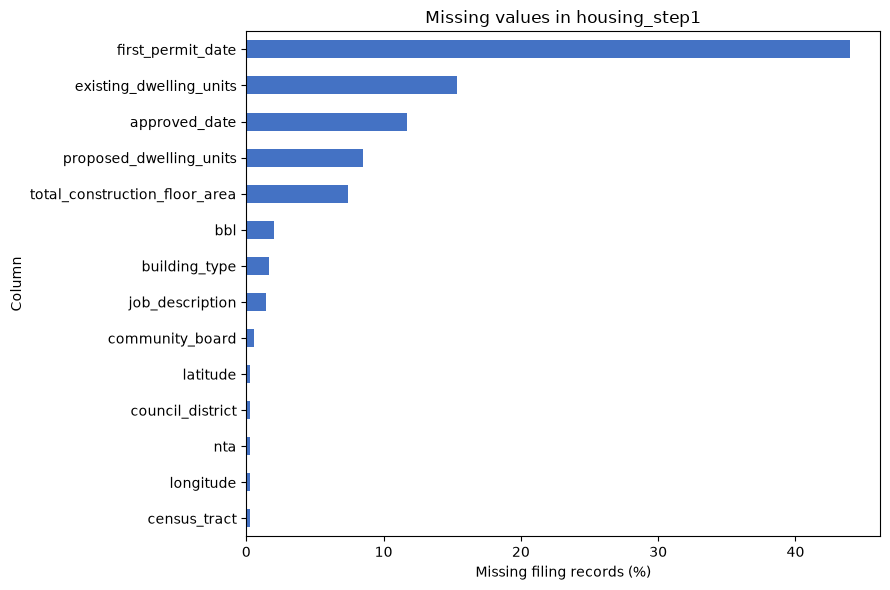

,approved_date,first_permit_date,rows
filing_status,,,
Approved,0.0%,99.8%,"276,042"
LOC Issued,13.5%,0.0%,"243,635"
Permit Entire,12.7%,0.0%,"155,666"
Objections,100.0%,100.0%,"19,408"
Filing Withdrawn,48.2%,88.2%,"8,896"
TA Certificate of Operation Issued,0.0%,100.0%,"6,626"
Plan Examiner Review,100.0%,100.0%,"6,537"
CO Issued,0.0%,0.0%,"4,668"
Full Demolition Signed-off,7.3%,36.8%,"1,675"


In [4]:
missing_summary = (
    pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": df.isna().mean().mul(100),
    })
    .query("missing_count > 0")
    .sort_values("missing_percent", ascending=False)
)
display(missing_summary.style.format({"missing_percent": "{:.3f}%"}))

ax = missing_summary.sort_values("missing_percent")["missing_percent"].plot(
    kind="barh", figsize=(9, 6), color="#4472C4"
)
ax.set(title="Missing values in housing_step1", xlabel="Missing filing records (%)", ylabel="Column")
plt.tight_layout()
plt.show()

status_date_missing = (
    df.groupby("filing_status")[["approved_date", "first_permit_date"]]
      .agg(lambda s: s.isna().mean() * 100)
      .assign(rows=df["filing_status"].value_counts())
      .sort_values("rows", ascending=False)
      .head(15)
)
display(status_date_missing.style.format({"approved_date": "{:.1f}%", "first_permit_date": "{:.1f}%", "rows": "{:,}"}))

### Missingness findings

- `first_permit_date` has the largest missing share (321,095; 43.96%), followed by existing dwelling units (111,994; 15.33%), approval date (85,335; 11.68%), proposed dwelling units (62,341; 8.53%), and floor area (53,846; 7.37%).
- Permit/approval gaps are status-dependent. For example, almost every `Approved` row lacks a first permit date, while `Objections`, `Plan Examiner Review`, and `Incomplete` rows usually lack both dates. This supports retaining nulls as meaningful workflow state rather than imputing them.
- All 2,219 rows missing latitude also miss longitude, NTA, census tract, and council district, suggesting a common geocoding gap. No partial latitude/longitude pairs are present.
- The absence of missing `zip_code` and `filing_date` values is a result of Issa's earlier row exclusion, not evidence that the raw source had complete integration keys.

## 4. Filing records versus unique jobs

A `job_id` may have an initial filing plus later plan/application or subsequent filings. The comparisons below prevent filing volume from being mistaken for construction-job volume.

,filings_per_job
count,404597.000000
mean,1.805399
std,1.851606
min,1.000000
50%,1.000000
75%,2.000000
90%,3.000000
95%,5.000000
99%,10.000000
99.9%,20.000000


,filing_records,jobs_with_I1
job_type,,
Alteration,589720,336004
New Building,55097,8439
Alteration CO,49301,12614
ALT-CO - New Building with Existing Elements to Remain,16124,2511
No Work,12233,10307
Full Demolition,7984,5423


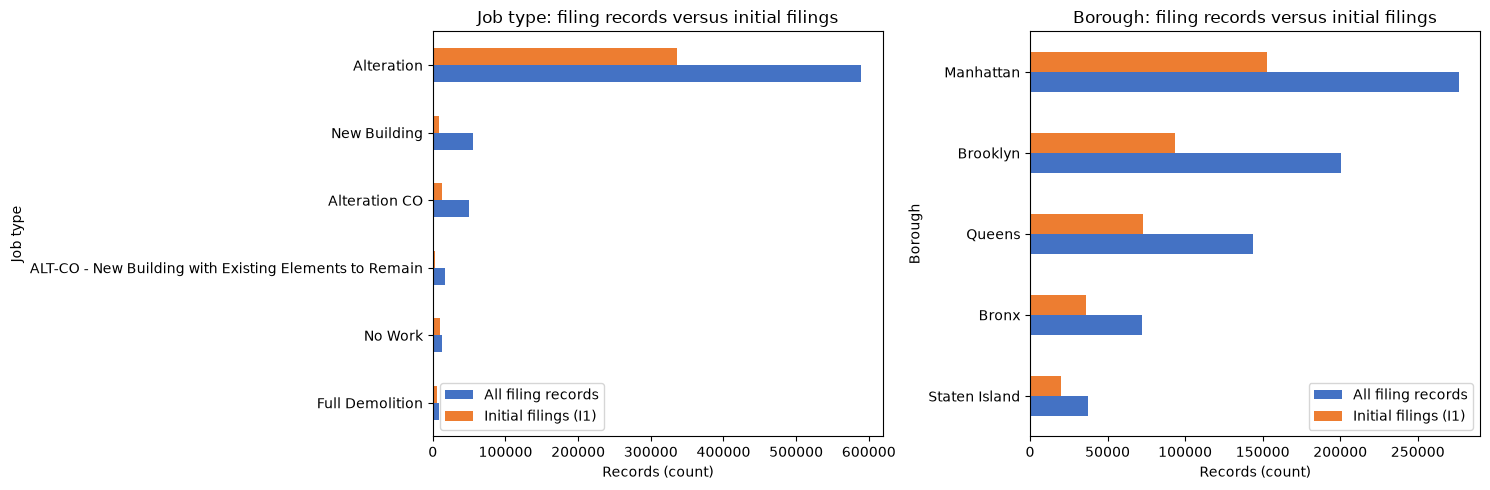

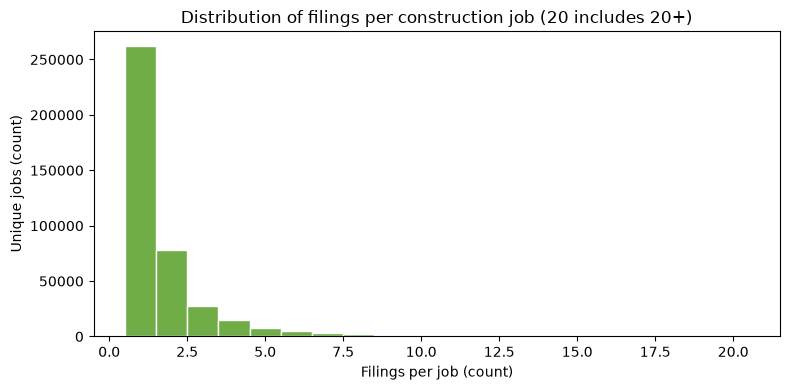

In [5]:
filings_per_job = df.groupby("job_id", sort=False).size()
display(filings_per_job.describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.999]).to_frame("filings_per_job"))

job_type_comparison = pd.concat([
    df["job_type"].value_counts().rename("filing_records"),
    df.loc[df["is_initial_filing"], "job_type"].value_counts().rename("jobs_with_I1"),
], axis=1).fillna(0).astype(int)
display(job_type_comparison)

borough_comparison = pd.concat([
    df["borough"].value_counts().rename("filing_records"),
    df.loc[df["is_initial_filing"], "borough"].value_counts().rename("jobs_with_I1"),
], axis=1).fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
job_type_comparison.sort_values("filing_records").plot.barh(ax=axes[0], color=["#4472C4", "#ED7D31"])
axes[0].set(title="Job type: filing records versus initial filings", xlabel="Records (count)", ylabel="Job type")
axes[0].legend(["All filing records", "Initial filings (I1)"])
borough_comparison.sort_values("filing_records").plot.barh(ax=axes[1], color=["#4472C4", "#ED7D31"])
axes[1].set(title="Borough: filing records versus initial filings", xlabel="Records (count)", ylabel="Borough")
axes[1].legend(["All filing records", "Initial filings (I1)"])
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
filings_per_job.clip(upper=20).plot.hist(bins=np.arange(0.5, 21.5, 1), ax=ax, color="#70AD47", edgecolor="white")
ax.set(title="Distribution of filings per construction job (20 includes 20+)", xlabel="Filings per job (count)", ylabel="Unique jobs (count)")
plt.tight_layout()
plt.show()

### Grain findings

- The file contains 730,459 filings for 404,597 jobs: an average of 1.81 filings per job. The median is one, the 99th percentile is ten, and the maximum is 45 filings for one job.
- Alterations dominate both views, but the gap between 589,720 alteration filing rows and 336,004 alteration `I1` rows demonstrates how filing counts can inflate job activity.
- `I1` rows are the basis for one-record-per-job calculations. The 29,299 jobs without an `I1` row in the window had their `I1` filed before 2022; they are excluded from job counts (section 18), so a job started before 2022 is never counted as new 2022 construction.

## 5. Categorical distributions and consistency

Counts below describe filing records. Category labels are also checked for whitespace/case variants before any later standardization.

,raw_unique,normalized_unique,leading_or_trailing_space_rows
column,,,
borough,5,5,0
job_type,6,6,0
building_type,4,4,0
filing_status,51,51,0
full_demolition_work_type_,2,2,0


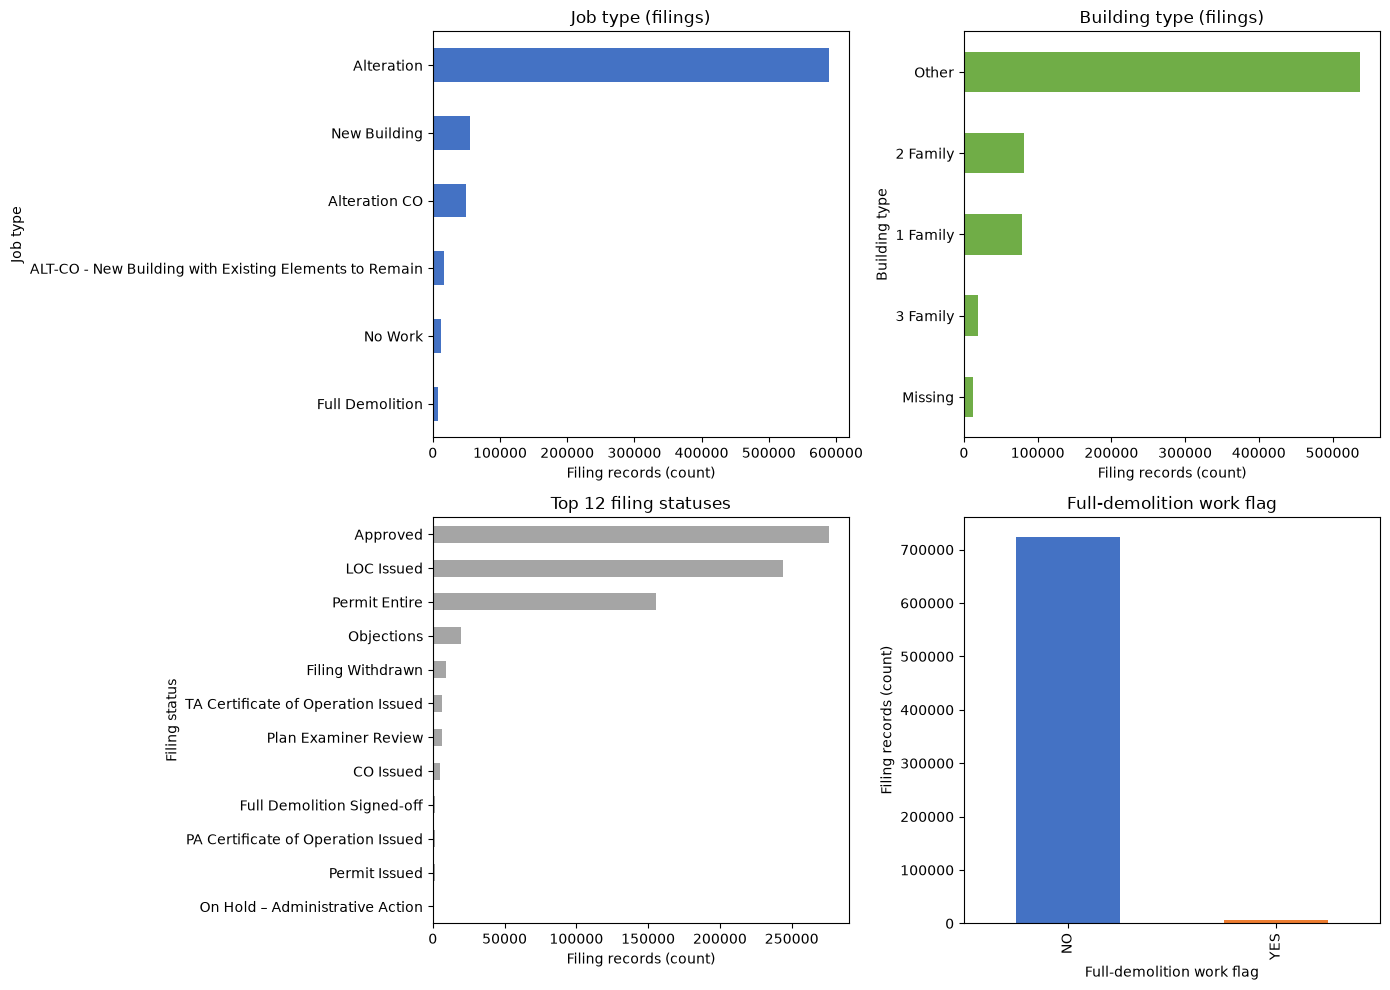

In [6]:
category_columns = ["borough", "job_type", "building_type", "filing_status", "full_demolition_work_type_"]
category_quality = []
for column in category_columns:
    raw = df[column].dropna().astype("string")
    normalized = raw.str.strip().str.casefold()
    category_quality.append({
        "column": column,
        "raw_unique": raw.nunique(),
        "normalized_unique": normalized.nunique(),
        "leading_or_trailing_space_rows": int((raw != raw.str.strip()).sum()),
    })
display(pd.DataFrame(category_quality).set_index("column"))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
df["job_type"].value_counts().sort_values().plot.barh(ax=axes[0, 0], color="#4472C4", title="Job type (filings)")
df["building_type"].fillna("Missing").value_counts().sort_values().plot.barh(ax=axes[0, 1], color="#70AD47", title="Building type (filings)")
df["filing_status"].value_counts().head(12).sort_values().plot.barh(ax=axes[1, 0], color="#A5A5A5", title="Top 12 filing statuses")
df["full_demolition_work_type_"].value_counts().plot.bar(ax=axes[1, 1], color=["#4472C4", "#ED7D31"], title="Full-demolition work flag")
for ax, y_label in zip(axes.flat[:3], ["Job type", "Building type", "Filing status"]):
    ax.set_xlabel("Filing records (count)")
    ax.set_ylabel(y_label)
axes[1, 1].set_xlabel("Full-demolition work flag")
axes[1, 1].set_ylabel("Filing records (count)")
plt.tight_layout()
plt.show()

### Categorical findings

- No whitespace/case-only duplicates were found in borough, job type, building type, filing status, or demolition flag labels. Borough already uses the five agreed canonical names.
- Alteration accounts for 589,720 filings; Manhattan has the most filing records (276,306). These are workload/filing distributions, not counts of completed buildings.
- `building_type` is mostly `Other` (537,515 rows) and is missing in 12,236 rows. In this window no building type occurs only once, so no consolidation of rare labels is needed.
- The 51 filing statuses are operational workflow states. No whitespace/case or encoding variant was verified in the retained categorical labels.

## 6. Numerical distributions and outlier investigation

Construction variables are strongly right-skewed. IQR flags are used only to find records for investigation; they are **not** deletion rules. Log-scale plots reveal the distribution without changing the data.

In [7]:
numeric_focus = [
    "initial_cost", "total_construction_floor_area",
    "existing_dwelling_units", "proposed_dwelling_units"
]
description = df[numeric_focus].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
).T
display(description.style.format("{:,.2f}"))

outlier_rows = []
for column in numeric_focus:
    values = df[column]
    q1, q3 = values.quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    outlier_rows.append({
        "column": column,
        "missing": int(values.isna().sum()),
        "negative": int((values < 0).sum()),
        "zero": int((values == 0).sum()),
        "non_integer": int(((values.dropna() % 1) != 0).sum()),
        "infinite": int(np.isinf(values).sum()),
        "IQR_upper_fence": upper,
        "above_upper_fence": int((values > upper).sum()),
        "maximum": values.max(),
    })
outlier_summary = pd.DataFrame(outlier_rows).set_index("column")
display(outlier_summary.style.format({"IQR_upper_fence": "{:,.2f}", "maximum": "{:,.2f}"}))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.9%,max
initial_cost,"730,459.00","285,760.33","3,806,434.66",0.00,0.00,0.00,"5,000.00","25,000.00","99,500.00","793,205.90","4,000,000.00","25,194,440.00","800,010,000.00"
total_construction_floor_area,"676,613.00","22,543.25","1,203,412.19",0.00,1.00,8.00,500.00,"2,000.00","5,880.00","73,116.00","327,031.00","1,351,000.00","770,010,000.00"
existing_dwelling_units,"618,465.00",221.65,"141,290.33",0.00,0.00,0.00,0.00,2.00,19.00,209.00,497.00,"1,092.00","111,111,111.00"
proposed_dwelling_units,"668,118.00",44.88,"1,039.76",0.00,0.00,0.00,0.00,2.00,25.00,221.00,521.00,"1,100.88","325,437.00"


,missing,negative,zero,non_integer,infinite,IQR_upper_fence,above_upper_fence,maximum
column,,,,,,,,
initial_cost,0,0,69193,34675,0,"241,250.00",100230,"800,010,000.00"
total_construction_floor_area,53846,0,698,53496,0,"13,950.00",100549,"770,010,000.00"
existing_dwelling_units,111994,0,227998,0,0,47.50,112169,"111,111,111.00"
proposed_dwelling_units,62341,0,216681,0,0,62.50,111327,"325,437.00"


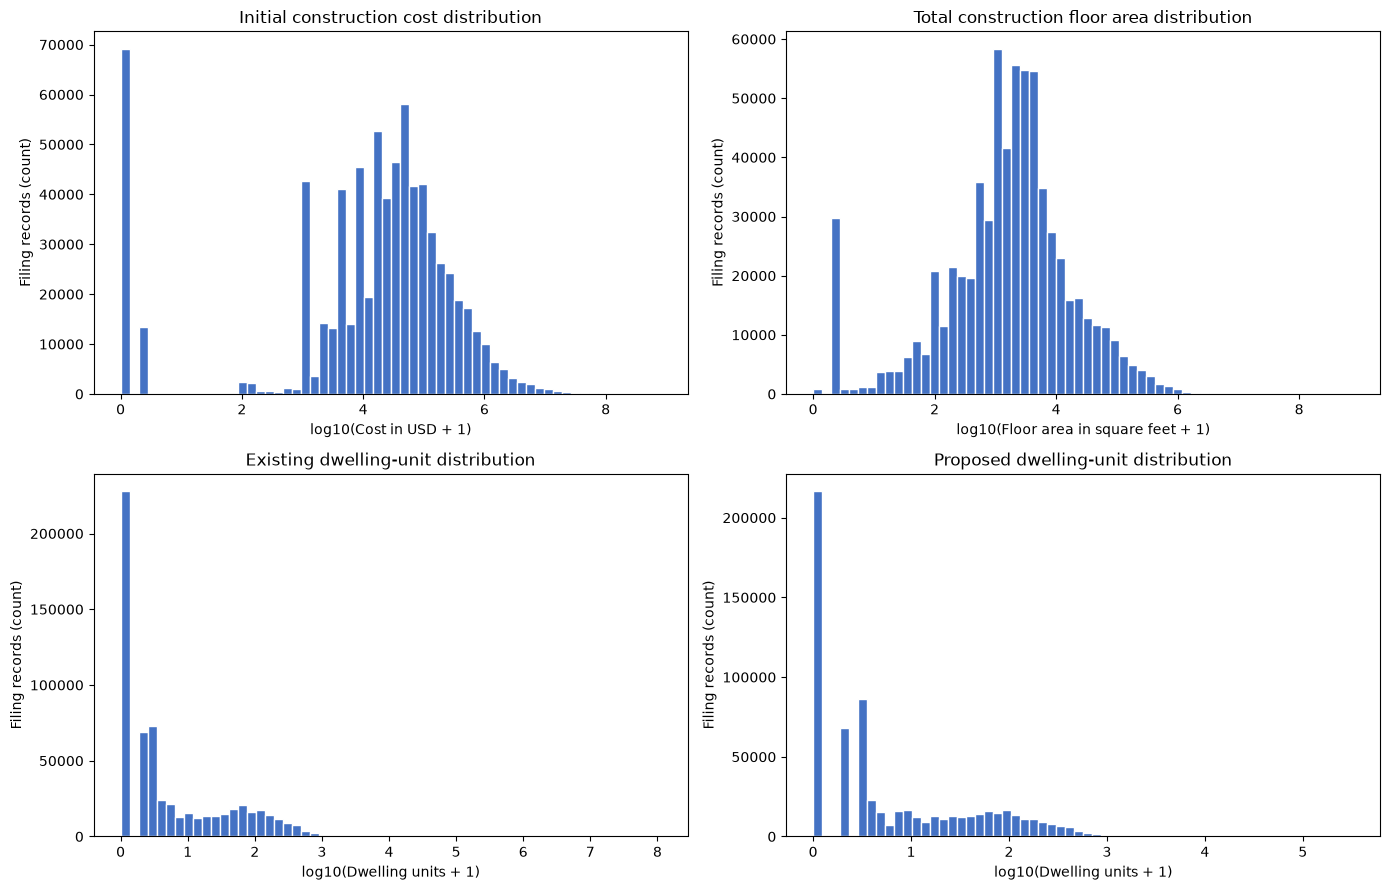

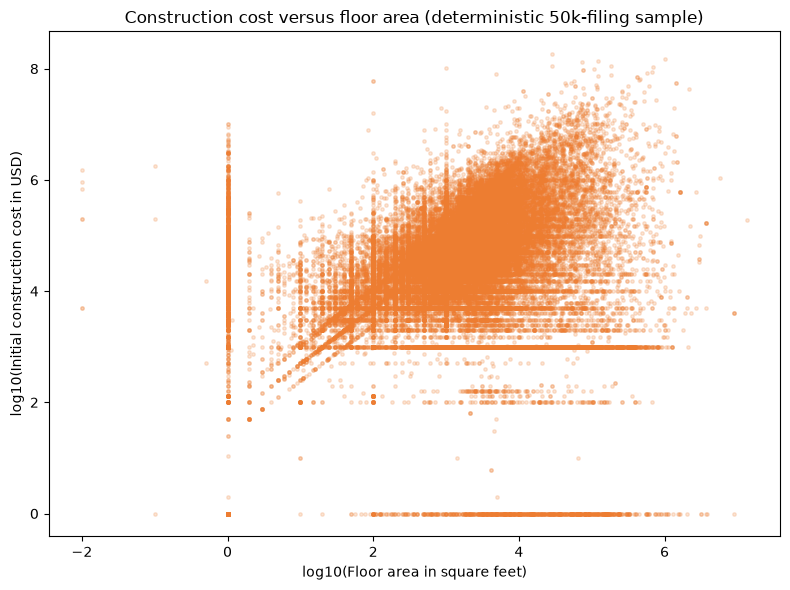

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_labels = {
    "initial_cost": ("Initial construction cost distribution", "log10(Cost in USD + 1)"),
    "total_construction_floor_area": ("Total construction floor area distribution", "log10(Floor area in square feet + 1)"),
    "existing_dwelling_units": ("Existing dwelling-unit distribution", "log10(Dwelling units + 1)"),
    "proposed_dwelling_units": ("Proposed dwelling-unit distribution", "log10(Dwelling units + 1)"),
}
for ax, column in zip(axes.flat, numeric_focus):
    values = df[column].dropna()
    ax.hist(np.log10(values + 1), bins=60, color="#4472C4", edgecolor="white")
    title, x_label = plot_labels[column]
    ax.set(title=title, xlabel=x_label, ylabel="Filing records (count)")
plt.tight_layout()
plt.show()

positive_cost_area = df.loc[
    (df["initial_cost"] > 0) & (df["total_construction_floor_area"] > 0),
    ["initial_cost", "total_construction_floor_area", "job_type"]
]
scatter_sample = positive_cost_area.sample(n=min(50_000, len(positive_cost_area)), random_state=42)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    np.log10(scatter_sample["total_construction_floor_area"]),
    np.log10(scatter_sample["initial_cost"]),
    s=6, alpha=0.20, color="#ED7D31"
)
ax.set(title="Construction cost versus floor area (deterministic 50k-filing sample)", xlabel="log10(Floor area in square feet)", ylabel="log10(Initial construction cost in USD)")
plt.tight_layout()
plt.show()

Top five records by initial_cost:


,job_filing_number,job_id,is_initial_filing,job_type,borough,zip_code,initial_cost
329358,S00549493-P1,S00549493,False,Alteration,Staten Island,10301,800010000.0
522338,S00549493-P2,S00549493,False,Alteration,Staten Island,10301,800010000.0
512821,M00615380-P2,M00615380,False,New Building,Manhattan,10017,654000000.0
547086,M00615380-I1,M00615380,True,New Building,Manhattan,10017,654000000.0
295637,B00944006-P1,B00944006,False,Alteration,Brooklyn,11218,625000000.0


Top five records by total_construction_floor_area:


,job_filing_number,job_id,is_initial_filing,job_type,borough,zip_code,total_construction_floor_area
264674,M00964618-I1,M00964618,True,Alteration,Manhattan,10065,770010000.0
606675,B01249011-S1,B01249011,False,Alteration,Brooklyn,11216,432000000.0
93824,X00429035-I1,X00429035,True,Alteration,Bronx,10459,240283000.0
287601,X00508690-P1,X00508690,False,Alteration,Bronx,10451,220152000.0
105992,B00727069-I1,B00727069,True,Alteration,Brooklyn,11210,200036000.0


Top five records by existing_dwelling_units:


,job_filing_number,job_id,is_initial_filing,job_type,borough,zip_code,existing_dwelling_units
23770,S00542058-I1,S00542058,True,Alteration,Staten Island,10306,111111111.0
68220,B00336793-P1,B00336793,False,Alteration,Brooklyn,11233,325437.0
293531,B00336793-P2,B00336793,False,Alteration,Brooklyn,11233,325437.0
338879,B00336793-P3,B00336793,False,Alteration,Brooklyn,11233,325437.0
348390,B00336793-P4,B00336793,False,Alteration,Brooklyn,11233,325437.0


Top five records by proposed_dwelling_units:


,job_filing_number,job_id,is_initial_filing,job_type,borough,zip_code,proposed_dwelling_units
68220,B00336793-P1,B00336793,False,Alteration,Brooklyn,11233,325437.0
293531,B00336793-P2,B00336793,False,Alteration,Brooklyn,11233,325437.0
338879,B00336793-P3,B00336793,False,Alteration,Brooklyn,11233,325437.0
348390,B00336793-P4,B00336793,False,Alteration,Brooklyn,11233,325437.0
196430,M00961030-P1,M00961030,False,Alteration,Manhattan,10025,294294.0


,value
rows_with_both_unit_fields,612136.0
negative_change,19950.0
no_change,541507.0
positive_change,50679.0
minimum,-111111110.0
maximum,8343.0


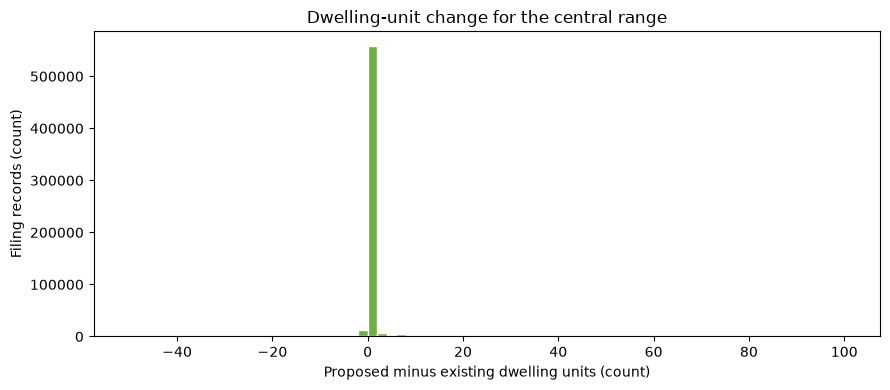

In [9]:
extreme_columns = ["job_filing_number", "job_id", "is_initial_filing", "job_type", "borough", "zip_code"]
for column in numeric_focus:
    print(f"Top five records by {column}:")
    display(df.nlargest(5, column)[extreme_columns + [column]])

dwelling_delta = df["proposed_dwelling_units"] - df["existing_dwelling_units"]
delta_summary = pd.Series({
    "rows_with_both_unit_fields": dwelling_delta.notna().sum(),
    "negative_change": (dwelling_delta < 0).sum(),
    "no_change": (dwelling_delta == 0).sum(),
    "positive_change": (dwelling_delta > 0).sum(),
    "minimum": dwelling_delta.min(),
    "maximum": dwelling_delta.max(),
})
display(delta_summary.to_frame("value"))

fig, ax = plt.subplots(figsize=(9, 4))
dwelling_delta[dwelling_delta.between(-50, 100)].plot.hist(bins=75, ax=ax, color="#70AD47", edgecolor="white")
ax.set(title="Dwelling-unit change for the central range", xlabel="Proposed minus existing dwelling units (count)", ylabel="Filing records (count)")
plt.tight_layout()
plt.show()

### Numerical and outlier findings

- All four focus variables are non-negative and contain no infinity values. Dwelling-unit counts are integer-valued; cost and area contain legitimate-looking decimal values and should remain numeric rather than be forced to integers.
- Distributions are extremely right-skewed. Cost has median USD 25,000, 99th percentile USD 4 million, and maximum USD 800.01 million. Floor area has median 2,000, 99th percentile 327,031, and maximum 770.01 million.
- IQR screening flags 100,230 costs and 100,549 areas. These large counts show why automatic IQR deletion would remove many plausible major projects. Investigation should focus on implausible extremes and cross-field consistency.
- Several maxima are suspicious: 111,111,111 existing dwelling units and floor areas in the hundreds of millions are unlikely for one building filing. Repeated maxima across multiple filings of the same `job_id` also demonstrate why filing-level sums would overcount. These values need source verification, not automatic removal.
- Of 612,136 filings with both dwelling fields, 541,507 show no change, 50,679 show an increase, and 19,950 show a decrease. The largest decrease (-111,111,110) is driven by a suspicious existing-unit value, so means/totals are not reliable until investigated.
- There are 69,193 zero-cost filings, 697 positive-cost/zero-area filings, and 42,047 positive-area/zero-cost filings. Zero can reflect filing/work-type semantics, but these combinations require analysis by job type and filing suffix before aggregation.

## 7. ZIP-code and geographic quality assessment

ZIP codes are treated as identifiers. Format validation is definitive; the prefix screen and coordinate bounding box are only anomaly screens and are not substitutes for an authoritative NYC ZIP reference.

,value
missing_zip,0
non_five_digit_zip,0
unique_zip_values,225
rows_outside_prefix_screen,24
ZIPs_observed_in_multiple_boroughs,3
both_coordinates_missing,2219
partial_coordinate_pairs,0
coordinates_outside_exploratory_NYC_box,0


Rows outside the non-authoritative prefix screen:


,job_filing_number,borough,zip_code,latitude,longitude
54178,X00780062-I1,Bronx,10803,40.883690,-73.795372
346086,X00920483-S2,Bronx,10803,40.884573,-73.799257
348568,X00920483-P1,Bronx,10803,40.884573,-73.799257
355251,X00920483-P3,Bronx,10803,40.884573,-73.799257
360560,X00920483-P2,Bronx,10803,40.884573,-73.799257
414943,X00920483-S1,Bronx,10803,40.884573,-73.799257
430187,X00920483-S5,Bronx,10803,40.884573,-73.799257
443884,X00974000-P3,Bronx,10803,40.884021,-73.796181
454952,X00920483-P5,Bronx,10803,40.884573,-73.799257
457266,X00974000-P4,Bronx,10803,40.884021,-73.796181


ZIP values observed with more than one borough label:


borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
zip_code,,,,,
10463,3503,0,299,0,0
11208,0,4176,0,3,0
11370,31,0,0,962,0


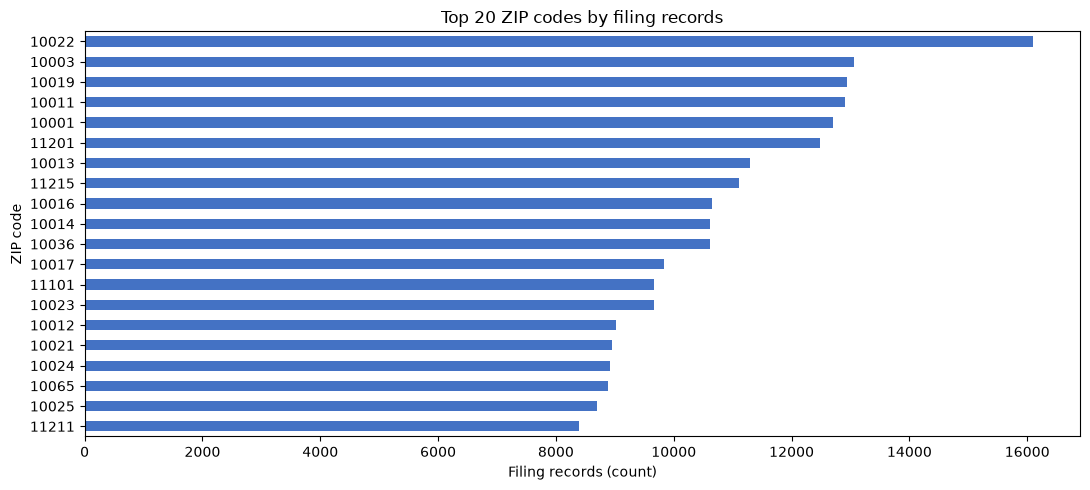

In [10]:
zip_format_valid = df["zip_code"].str.fullmatch(r"\d{5}", na=False)
nyc_style_prefixes = ("100", "101", "102", "103", "104", "110", "111", "112", "113", "114", "116")
unexpected_prefix = ~df["zip_code"].str.startswith(nyc_style_prefixes, na=False)
zip_borough = pd.crosstab(df["zip_code"], df["borough"])
multi_borough_zips = zip_borough.loc[(zip_borough > 0).sum(axis=1) > 1]

geo_quality = pd.Series({
    "missing_zip": df["zip_code"].isna().sum(),
    "non_five_digit_zip": (~zip_format_valid).sum(),
    "unique_zip_values": df["zip_code"].nunique(),
    "rows_outside_prefix_screen": unexpected_prefix.sum(),
    "ZIPs_observed_in_multiple_boroughs": len(multi_borough_zips),
    "both_coordinates_missing": df[["latitude", "longitude"]].isna().all(axis=1).sum(),
    "partial_coordinate_pairs": (df[["latitude", "longitude"]].isna().any(axis=1) & ~df[["latitude", "longitude"]].isna().all(axis=1)).sum(),
    "coordinates_outside_exploratory_NYC_box": (
        df["latitude"].notna() &
        (~df["latitude"].between(40.49, 40.93) | ~df["longitude"].between(-74.27, -73.68))
    ).sum(),
})
display(geo_quality.to_frame("value"))

print("Rows outside the non-authoritative prefix screen:")
display(df.loc[unexpected_prefix, ["job_filing_number", "borough", "zip_code", "latitude", "longitude"]].drop_duplicates().head(30))
print("ZIP values observed with more than one borough label:")
display(multi_borough_zips)

fig, ax = plt.subplots(figsize=(11, 5))
df["zip_code"].value_counts().head(20).sort_values().plot.barh(ax=ax, color="#4472C4")
ax.set(title="Top 20 ZIP codes by filing records", xlabel="Filing records (count)", ylabel="ZIP code")
plt.tight_layout()
plt.show()

### ZIP and geography findings

- All retained ZIP values are five-character numeric strings, and none are missing. This verifies formatting only, not NYC membership.
- The prefix screen finds 24 rows: 23 use `10803` and one Staten Island record uses `01226`. `01226` is especially suspicious and lacks coordinates; it should be verified against the source/address. `10803` rows have Bronx-like coordinates, so they may reflect postal-border semantics or a source error and should not be changed without an authoritative lookup.
- ZIPs `10463`, `11208`, and `11370` appear under more than one borough. The minority rows could be boundary/geocoding cases; inspect address/coordinates and an approved ZIP reference rather than overwriting borough values.
- Exactly 2,219 rows lack both coordinates. All available coordinates fall inside the broad exploratory NYC bounding box, but that box is too coarse to prove borough correctness.

## 8. Date quality and temporal patterns

Dates are parsed into separate analytical series so this EDA does not mutate the input dataframe. The audit date is 2026-11-03 (Egypt local date). Filing date is the proposed integration event date, but it represents application filing—not construction start or completion.

,raw_missing,parse_failures_among_non_missing,minimum,maximum,after_audit_date
column,,,,,
filing_date,0,0,2022-01-01 00:00:00,2026-10-31 23:00:00,0
approved_date,85335,0,2021-03-10 08:35:36,2026-11-05 22:57:36,650
first_permit_date,321095,0,2021-05-06 00:00:00,2026-11-05 00:00:00,887
current_status_date,0,0,2022-01-03 15:29:22,2026-11-06 05:20:49,5545


,comparable_rows,earlier_than_filing
date_column,,
approved_date,645124,27
first_permit_date,409364,16
current_status_date,730459,14


,filing_records,jobs_with_I1
filing_date,,
2022,141685,88790
2023,141667,74460
2024,155824,78713
2025,158814,75636
2026,132469,57699


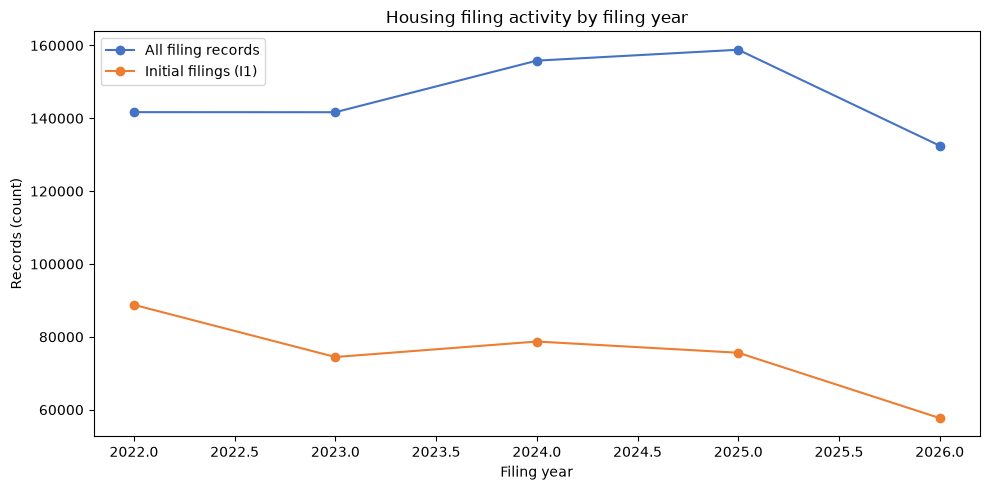

In [11]:
date_columns = ["filing_date", "approved_date", "first_permit_date", "current_status_date"]
parsed_dates = pd.DataFrame({
    column: pd.to_datetime(df[column], format="mixed", errors="coerce")
    for column in date_columns
})
audit_cutoff = pd.Timestamp("2026-11-03 23:59:59")
date_quality_rows = []
for column in date_columns:
    parsed = parsed_dates[column]
    date_quality_rows.append({
        "column": column,
        "raw_missing": int(df[column].isna().sum()),
        "parse_failures_among_non_missing": int((df[column].notna() & parsed.isna()).sum()),
        "minimum": parsed.min(),
        "maximum": parsed.max(),
        "after_audit_date": int((parsed > audit_cutoff).sum()),
    })
date_quality = pd.DataFrame(date_quality_rows).set_index("column")
display(date_quality)

filing = parsed_dates["filing_date"]
order_checks = []
for column in ["approved_date", "first_permit_date", "current_status_date"]:
    comparison = parsed_dates[column]
    order_checks.append({
        "date_column": column,
        "comparable_rows": int((filing.notna() & comparison.notna()).sum()),
        "earlier_than_filing": int((comparison < filing).sum()),
    })
display(pd.DataFrame(order_checks).set_index("date_column"))

annual_activity = pd.concat([
    filing.dt.year.value_counts().sort_index().rename("filing_records"),
    filing[df["is_initial_filing"]].dt.year.value_counts().sort_index().rename("jobs_with_I1"),
], axis=1).fillna(0).astype(int)
display(annual_activity)
ax = annual_activity.plot(figsize=(10, 5), marker="o", color=["#4472C4", "#ED7D31"])
ax.set(title="Housing filing activity by filing year", xlabel="Filing year", ylabel="Records (count)")
ax.legend(["All filing records", "Initial filings (I1)"])
plt.tight_layout()
plt.show()

### Date findings

- Every non-missing date parses successfully. Filing dates range from 2022-01-01 to 2026-10-31 (the team scope). Approval, permit and status dates run later, to 2026-11-06, because those workflow events happen after filing; none is later than the download.
- Filings per year are 141,685 (2022), 141,667 (2023), 155,824 (2024), 158,814 (2025) and 132,469 (2026, January to October only). 2026 is a partial year and must not be compared directly with the full years.
- There are 27 approvals, 16 first-permit dates, and 14 current-status dates earlier than filing timestamps. Many same-day permit cases differ because filing has a time while permit is stored at midnight; however, the largest gaps exceed years and need record-level review.
- Dates are stored as text in the first-stage input. The cleaning section below parses them with explicit failure reporting, compares calendar dates correctly, and derives nullable integer `year` from `filing_date`.

## 9. Cross-field inconsistency checks

These checks identify records for source review. A mismatch may reflect different field definitions rather than an error.

In [12]:
filing_suffix = df["job_filing_number"].str.rsplit("-", n=1).str[-1]
suffix_family = filing_suffix.str.extract(r"^([A-Z]+)", expand=False)

cross_field_checks = pd.Series({
    "job_id format failures": (~df["job_id"].str.fullmatch(r"[A-Z]\d{8}", na=False)).sum(),
    "filings outside I/P/S suffix families": (~suffix_family.isin(["I", "P", "S"])).sum(),
    "job IDs with multiple job_type values": (df.groupby("job_id")["job_type"].nunique() > 1).sum(),
    "Full Demolition job_type with demolition flag NO": ((df["job_type"] == "Full Demolition") & (df["full_demolition_work_type_"] == "NO")).sum(),
    "positive cost with zero floor area": ((df["initial_cost"] > 0) & (df["total_construction_floor_area"] == 0)).sum(),
    "positive floor area with zero cost": ((df["total_construction_floor_area"] > 0) & (df["initial_cost"] == 0)).sum(),
    "New Building rows with zero cost": ((df["job_type"] == "New Building") & (df["initial_cost"] == 0)).sum(),
})
display(cross_field_checks.to_frame("rows_or_groups"))

print("Filing suffix families (these are source categories, not assumed errors):")
display(suffix_family.value_counts(dropna=False).to_frame("filing_records"))
print("Demolition job type versus work flag:")
display(pd.crosstab(df["job_type"], df["full_demolition_work_type_"]))

,rows_or_groups
job_id format failures,0
filings outside I/P/S suffix families,8391
job IDs with multiple job_type values,15
Full Demolition job_type with demolition flag NO,1890
positive cost with zero floor area,697
positive floor area with zero cost,42047
New Building rows with zero cost,35252


Filing suffix families (these are source categories, not assumed errors):


,filing_records
job_filing_number,
I,375298
P,224973
S,121797
A,5448
Z,1881
B,825
C,140
Y,53
AR,25


Demolition job type versus work flag:


full_demolition_work_type_,NO,YES
job_type,,
ALT-CO - New Building with Existing Elements to Remain,16124,0
Alteration,589720,0
Alteration CO,49301,0
Full Demolition,1890,6094
New Building,55097,0
No Work,12233,0


### Inconsistency findings

- Every derived `job_id` follows the observed letter-plus-eight-digits structure. There are 8,391 filings in suffix families other than I/P/S (mostly A, Z, and B). These appear to be legitimate source filing categories, so an I/P/S-only regex must not be used to reject them.
- Fifteen job IDs have more than one `job_type`. Job-level analysis should use a documented representative record (often `I1` when present) and inspect these 15 exceptions.
- Of 7,984 rows with `job_type == 'Full Demolition'`, 1,890 have the separate demolition work flag set to `NO`. The fields may encode different concepts; verify the data dictionary before treating this as contradictory.
- Zero and mismatched cost/area combinations are numerous, especially across later filings. They should be profiled by suffix and job type and deduplicated at the intended job grain before totals are calculated.

## 10. EDA-derived cleaning decision plan

The following EDA recommendations define the cleaning work implemented in Sections 11–16. Items that cannot be resolved from the available evidence remain flagged rather than silently changed.

1. Parse the four date fields to nullable datetimes with an explicit parse-failure report; derive nullable integer `year` from `filing_date`. Preserve the raw text columns until validation is accepted.
2. Keep `zip_code` as a five-character string, but validate membership and borough consistency against an agreed authoritative NYC ZIP reference. Investigate `01226`, the `10803` records, and minority-borough rows for `10463`, `11208`, and `11370`; do not infer replacements from prefix alone.
3. Verify suspicious numeric extremes against the NYC source, especially 111,111,111 existing units and floor areas in the hundreds of millions. Define field-specific validity decisions; do not delete all IQR outliers.
4. Treat zero cost, zero area, and dwelling-unit values separately from missing values. Profile them by job type and suffix before deciding whether they mean 'not applicable', 'not reported', or a real zero.
5. Review the two one-off building types against source values and the data dictionary before deciding whether they need category consolidation.
6. Establish a job-level representative-row rule for attributes used in aggregation. Count jobs from `I1` rows (the agreed rule, section 18); for attributes, document the exclusion of the 29,299 jobs without an `I1` in the window and handle the 15 multi-job-type cases. Never sum repeated filing-level cost/area/unit values without a grain rule.
7. In a reproducible rerun from raw data, retain an audit table for rows excluded due to missing integration keys, and make repeated-filing selection deterministic using an authoritative version/update key or an explicit tie-break.

### Limitations

This audit cannot reconstruct raw-source removals because the historical raw snapshot is unavailable. The dataset describes DOB NOW application filings, not completed construction; filing, approval, and permit dates represent different workflow events; estimated costs may differ from actual costs; and proposed units are not completed housing. The 2026 year is partial (January to October). Findings are descriptive and do not imply causation.

## Contribution note

Mohamed Issa authored Stage 1 housing cleaning in `phase1_housing_initial_cleaning_issa.ipynb` and produced `data/housing_step1.csv.gz`. Mohamed Walid authored Stage 2 housing EDA, additional cleaning, standardization, export, and validation in this notebook. Issa's notebook and Stage 1 output were reviewed but not modified.

# Part II — Housing cleaning, standardization, and validation

## 11. Cleaning scope and authoritative evidence

The cleaning pipeline starts from a copy of `df`, preserves every filing row and identifier, and records uncertain cases with quality flags. It does not aggregate jobs or join transportation data. The following official sources were consulted on **2026-11-03**:

- [DOB NOW: Build — Job Application Filings](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd): confirms the source fields and reproduces the inspected extreme values. Reproduction confirms transcription, not correctness.
- [NYC Primary Land Use Tax Lot Output (PLUTO)](https://data.cityofnewyork.us/City-Government/Primary-Land-Use-Tax-Lot-Output-PLUTO-/64uk-42ks): provides authoritative tax-lot address and ZIP attributes. PLUTO matches `37 MCGEE LANE` to `10303`; it also confirms the Bronx tax lots using `10803` and the cross-boundary examples for `11208`.
- [NYC Geosupport User Programming Guide](https://www.nyc.gov/assets/planning/download/pdf/data-maps/open-data/upg.pdf): documents that Marble Hill is legally Manhattan but uses Bronx ZIP `10463`, and Rikers Island is legally Bronx while serviced through Queens. These explain the observed `10463` and `11370` cross-borough combinations.

The contract lists `housing_cleaned.csv.gz` only as a **proposed example** and says future names require receiver confirmation. The active assignment explicitly selects `data/housing_step2.csv.gz`; this notebook uses that requested handoff name and does not alter the contract.

In [13]:
# Work on a separate dataframe; the loaded first-stage dataframe remains unchanged.
clean_df = df.copy()
rows_before_cleaning, columns_before_cleaning = df.shape

def append_quality_note(values, mask, label):
    """Append a semicolon-delimited label to an object array in place."""
    mask = np.asarray(mask, dtype=bool)
    values[mask] = np.where(values[mask] == "", label, values[mask] + ";" + label)

# Field-specific boundaries distinguish invalid magnitudes from review-only extremes.
# They are intentionally much higher than ordinary IQR fences.
FLOOR_AREA_INVALID_THRESHOLD = 100_000_000   # square feet for one filing
DWELLING_UNITS_INVALID_THRESHOLD = 100_000  # units for one building filing
FLOOR_AREA_REVIEW_THRESHOLD = 10_000_000
DWELLING_UNITS_REVIEW_THRESHOLD = 10_000
INITIAL_COST_REVIEW_THRESHOLD = 100_000_000

initial_cost_zero = df["initial_cost"].eq(0)
floor_area_zero = df["total_construction_floor_area"].eq(0)
invalid_floor_area = df["total_construction_floor_area"].gt(FLOOR_AREA_INVALID_THRESHOLD)
invalid_existing_units = df["existing_dwelling_units"].gt(DWELLING_UNITS_INVALID_THRESHOLD)
invalid_proposed_units = df["proposed_dwelling_units"].gt(DWELLING_UNITS_INVALID_THRESHOLD)
numeric_outlier_review = (
    df["initial_cost"].gt(INITIAL_COST_REVIEW_THRESHOLD)
    | df["total_construction_floor_area"].gt(FLOOR_AREA_REVIEW_THRESHOLD)
    | df["existing_dwelling_units"].gt(DWELLING_UNITS_REVIEW_THRESHOLD)
    | df["proposed_dwelling_units"].gt(DWELLING_UNITS_REVIEW_THRESHOLD)
)

numeric_investigation = pd.DataFrame([
    {"check": "initial_cost equals zero (preserve + flag)", "affected_rows": int(initial_cost_zero.sum())},
    {"check": "floor area equals zero (preserve + flag)", "affected_rows": int(floor_area_zero.sum())},
    {"check": "any numeric review threshold exceeded (preserve/flag unless invalid rule below)", "affected_rows": int(numeric_outlier_review.sum())},
    {"check": "floor area > 100 million (set field missing)", "affected_rows": int(invalid_floor_area.sum())},
    {"check": "existing units > 100,000 (set field missing)", "affected_rows": int(invalid_existing_units.sum())},
    {"check": "proposed units > 100,000 (set field missing)", "affected_rows": int(invalid_proposed_units.sum())},
])
display(numeric_investigation)

,check,affected_rows
0,initial_cost equals zero (preserve + flag),69193
1,floor area equals zero (preserve + flag),698
2,any numeric review threshold exceeded (preserv...,153
3,floor area > 100 million (set field missing),8
4,"existing units > 100,000 (set field missing)",9
5,"proposed units > 100,000 (set field missing)",8


In [14]:
# Preserve meaningful/uncertain zero and extreme observations with explicit flags.
clean_df["initial_cost_zero_flag"] = initial_cost_zero
clean_df["floor_area_zero_flag"] = floor_area_zero
clean_df["numeric_outlier_review_flag"] = numeric_outlier_review

numeric_notes = np.full(len(clean_df), "", dtype=object)
append_quality_note(numeric_notes, invalid_floor_area, "floor_area_gt_100m_set_missing")
append_quality_note(numeric_notes, invalid_existing_units, "existing_units_gt_100k_set_missing")
append_quality_note(numeric_notes, invalid_proposed_units, "proposed_units_gt_100k_set_missing")
clean_df["numeric_correction_note"] = (
    pd.Series(numeric_notes, index=clean_df.index).replace("", pd.NA).astype("string")
)

# Change only the invalid attribute; never delete the filing row or invent a replacement.
clean_df.loc[invalid_floor_area, "total_construction_floor_area"] = np.nan
clean_df.loc[invalid_existing_units, "existing_dwelling_units"] = np.nan
clean_df.loc[invalid_proposed_units, "proposed_dwelling_units"] = np.nan

# Dwelling counts are integer-valued in the source and require nullable types after corrections.
clean_df["existing_dwelling_units"] = clean_df["existing_dwelling_units"].astype("Int64")
clean_df["proposed_dwelling_units"] = clean_df["proposed_dwelling_units"].astype("Int64")

numeric_corrected_record = clean_df["numeric_correction_note"].notna()
numeric_unresolved_review = clean_df["numeric_outlier_review_flag"] & ~numeric_corrected_record
numeric_review_summary = pd.Series({
    "originally_above_review_thresholds": int(clean_df["numeric_outlier_review_flag"].sum()),
    "received_invalid_value_correction": int(numeric_corrected_record.sum()),
    "retained_unresolved_for_review": int(numeric_unresolved_review.sum()),
})
display(numeric_review_summary.to_frame("filing_records"))
display(clean_df["numeric_correction_note"].value_counts(dropna=False).to_frame("filing_records"))
print("Rows retained after numeric cleaning:", len(clean_df))

,filing_records
originally_above_review_thresholds,153
received_invalid_value_correction,17
retained_unresolved_for_review,136


,filing_records
numeric_correction_note,
<NA>,730442
existing_units_gt_100k_set_missing;proposed_units_gt_100k_set_missing,8
floor_area_gt_100m_set_missing,8
existing_units_gt_100k_set_missing,1


Rows retained after numeric cleaning: 730459


### Numerical cleaning decisions

- **Zero cost and area are preserved.** The source contains filing scopes such as curb cuts, sheds, permits, or work filed in conjunction with another application. A zero may be meaningful or source-entered; replacing it with an average or missing value would invent information. Dedicated flags identify all 69,193 zero-cost and 698 zero-area rows.
- **Review history is separated from unresolved anomalies.** Exactly 153 records originally exceeded the conservative review thresholds. Of these, 17 distinct records received the justified invalid-value corrections described below, while 136 retain their original extreme values for later review. `numeric_outlier_review_flag` intentionally preserves the pre-cleaning investigation history; an unresolved case is defined as that flag being true while `numeric_correction_note` is missing. No extra output column is needed.
- **Eight floor-area values above 100 million square feet are set missing.** Inspected descriptions concern single buildings or limited work such as a sprinkler head, sidewalk shed, fence, or mechanical work; values resemble embedded job numbers and are not credible floor areas.
- **Nine existing-unit and eight proposed-unit values above 100,000 are set missing.** Examples include 111,111,111 units for a one-family fire renovation and 325,437 units for plumbing work. These are demonstrably incompatible with a single building filing. Values from 10,001 through 100,000 (13 existing-unit and 12 proposed-unit values) remain unchanged but flagged because evidence is insufficient for automatic correction.
- Only the affected attribute is made missing. No record is deleted, and the original values remain recoverable from `housing_step1.csv.gz` and traceable through `numeric_correction_note`.

## 12. Categorical and classification handling

EDA verified that the primary category labels already use consistent spelling, case, and surrounding whitespace. Therefore, no broad category normalization is justified. Unusual but source-valid values are preserved and uncertain cross-field combinations are flagged.

In [15]:
multi_type_jobs = (
    df.groupby("job_id")["job_type"].nunique().loc[lambda counts: counts > 1].index
)
classification_notes = np.full(len(clean_df), "", dtype=object)
append_quality_note(
    classification_notes, df["job_id"].isin(multi_type_jobs), "job_has_multiple_job_types"
)
append_quality_note(
    classification_notes,
    df["job_type"].eq("Full Demolition") & df["full_demolition_work_type_"].eq("NO"),
    "demolition_fields_differ_review_semantics",
)
append_quality_note(
    classification_notes,
    df["building_type"].isin(["Garage", "Office Bldg"]),
    "rare_building_type_preserved",
)
clean_df["classification_review_note"] = (
    pd.Series(classification_notes, index=clean_df.index).replace("", pd.NA).astype("string")
)
display(clean_df["classification_review_note"].value_counts(dropna=False).to_frame("filing_records"))

,filing_records
classification_review_note,
<NA>,728431
demolition_fields_differ_review_semantics,1890
job_has_multiple_job_types,138


### Classification decisions

- All filing suffix families are retained; the A, B, C, D, F, Y, Z, and AR families are source filing types, not malformed identifiers.
- `Garage` and `Office Bldg` each occur once but are meaningful building descriptions, so they are preserved rather than merged into `Other`.
- Fifteen jobs have more than one job type (138 filing rows), and 1,890 `Full Demolition` job rows carry a separate demolition-work flag of `NO`. Because the source fields may describe different filing concepts, the values are preserved and marked for semantic review rather than overwritten.
- `job_filing_number`, `job_id`, `is_initial_filing`, and every filing row remain intact. No job-level aggregation is performed.

## 13. ZIP-code standardization and geographic decisions

ZIP codes are standardized as trimmed five-character strings. Authoritative evidence supports exactly one correction; known boundary and cross-borough postal cases are preserved with a quality label. Borough values are not changed.

In [16]:
clean_df["zip_code"] = clean_df["zip_code"].astype("string").str.strip()
clean_df["zip_code_original"] = pd.Series(pd.NA, index=clean_df.index, dtype="string")
clean_df["zip_quality_flag"] = pd.Series("standard_five_digit", index=clean_df.index, dtype="string")

# Flag only the verified exceptional ZIP/borough combinations, not every row using the ZIP.
verified_cross_borough_case = (
    (clean_df["zip_code"].eq("10463") & clean_df["borough"].eq("Manhattan"))
    | (clean_df["zip_code"].eq("11208") & clean_df["borough"].eq("Queens"))
    | (clean_df["zip_code"].eq("11370") & clean_df["borough"].eq("Bronx"))
)
verified_unusual_postal_zip = (
    clean_df["zip_code"].eq("10803") & clean_df["borough"].eq("Bronx")
)
clean_df.loc[verified_cross_borough_case, "zip_quality_flag"] = "verified_cross_borough_case"
clean_df.loc[verified_unusual_postal_zip, "zip_quality_flag"] = "verified_unusual_postal_zip"

# Exact address match: DOB filing S01350874-I1 is 37 McGee Lane; NYC PLUTO reports ZIP 10303.
zip_correction_mask = (
    clean_df["job_filing_number"].eq("S01350874-I1")
    & clean_df["zip_code"].eq("01226")
)
if int(zip_correction_mask.sum()) != 1:
    raise ValueError("Expected exactly one verified 01226 ZIP correction target.")
clean_df.loc[zip_correction_mask, "zip_code_original"] = clean_df.loc[zip_correction_mask, "zip_code"]
clean_df.loc[zip_correction_mask, "zip_code"] = "10303"
clean_df.loc[zip_correction_mask, "zip_quality_flag"] = "corrected_from_PLUTO_address_match"

zip_exception_counts = pd.DataFrame([
    {"zip_code": "10463", "borough": "Manhattan", "quality_class": "verified_cross_borough_case", "filing_records": int((clean_df["zip_code"].eq("10463") & clean_df["borough"].eq("Manhattan")).sum())},
    {"zip_code": "10803", "borough": "Bronx", "quality_class": "verified_unusual_postal_zip", "filing_records": int((clean_df["zip_code"].eq("10803") & clean_df["borough"].eq("Bronx")).sum())},
    {"zip_code": "11208", "borough": "Queens", "quality_class": "verified_cross_borough_case", "filing_records": int((clean_df["zip_code"].eq("11208") & clean_df["borough"].eq("Queens")).sum())},
    {"zip_code": "11370", "borough": "Bronx", "quality_class": "verified_cross_borough_case", "filing_records": int((clean_df["zip_code"].eq("11370") & clean_df["borough"].eq("Bronx")).sum())},
])
display(zip_exception_counts)
display(clean_df["zip_quality_flag"].value_counts().to_frame("filing_records"))
display(clean_df.loc[zip_correction_mask, ["job_filing_number", "borough", "zip_code_original", "zip_code", "zip_quality_flag"]])
print("Non-five-digit ZIP values after standardization:", int((~clean_df["zip_code"].str.fullmatch(r"\d{5}", na=False)).sum()))

,zip_code,borough,quality_class,filing_records
0,10463,Manhattan,verified_cross_borough_case,299
1,10803,Bronx,verified_unusual_postal_zip,23
2,11208,Queens,verified_cross_borough_case,3
3,11370,Bronx,verified_cross_borough_case,31


,filing_records
zip_quality_flag,
standard_five_digit,730102
verified_cross_borough_case,333
verified_unusual_postal_zip,23
corrected_from_PLUTO_address_match,1


,job_filing_number,borough,zip_code_original,zip_code,zip_quality_flag
506490,S01350874-I1,Staten Island,01226,10303,corrected_from_PLUTO_address_match


Non-five-digit ZIP values after standardization: 0


### Geographic decisions

- Filing `S01350874-I1` changes from `01226` to `10303`. NYC PLUTO matches its exact address, 37 McGee Lane in Staten Island, to `10303`; `01226` also duplicates the source tax block and is not treated as a credible building ZIP. The original value is retained in `zip_code_original`.
- `10803` is preserved for the 23 Bronx filing rows because PLUTO returns `10803` for the matching Bronx tax lots near the Pelham boundary. Only the `10803`/Bronx combination is labelled `verified_unusual_postal_zip`.
- Only the exceptional `10463`/Manhattan (299 rows), `11208`/Queens (3 rows), and `11370`/Bronx (31 rows) combinations are labelled `verified_cross_borough_case`. The ordinary majority-borough combinations for those ZIPs remain `standard_five_digit`. Counts are recalculated from the loaded dataset rather than used as filtering constants.
- All final ZIP values are five-digit strings. Quality labels let Phase 2 decide transparently how boundary postal areas should participate in ZIP/year aggregation.

## 14. Date standardization and chronological validation

Chronology is evaluated on normalized calendar dates, not raw timestamps. This prevents a midnight-only permit time from being incorrectly called earlier when filing occurred later on the same day. Suspicious earlier-date records are preserved and flagged.

In [17]:
cleaning_date_columns = ["filing_date", "approved_date", "first_permit_date", "current_status_date"]
cleaning_parsed_dates = {
    column: pd.to_datetime(df[column], format="mixed", errors="coerce")
    for column in cleaning_date_columns
}
date_parse_failures = {
    column: int((df[column].notna() & cleaning_parsed_dates[column].isna()).sum())
    for column in cleaning_date_columns
}
filing_timestamp = cleaning_parsed_dates["filing_date"]
filing_calendar_date = filing_timestamp.dt.normalize()

chronology_rows = []
chronology_notes = np.full(len(clean_df), "", dtype=object)
chronology_specs = [
    ("approved_date", "approved_before_filing_date"),
    ("first_permit_date", "permit_before_filing_date"),
    ("current_status_date", "status_before_filing_date"),
]
for column, label in chronology_specs:
    comparison = cleaning_parsed_dates[column]
    same_day_earlier_time = (comparison < filing_timestamp) & (comparison.dt.normalize() == filing_calendar_date)
    genuinely_earlier_date = comparison.dt.normalize() < filing_calendar_date
    append_quality_note(chronology_notes, genuinely_earlier_date, label)
    chronology_rows.append({
        "column": column,
        "parse_failures_non_missing": date_parse_failures[column],
        "earlier_timestamp_same_day": int(same_day_earlier_time.sum()),
        "earlier_calendar_date": int(genuinely_earlier_date.sum()),
    })

clean_df["chronology_quality_flag"] = (
    pd.Series(chronology_notes, index=clean_df.index).replace("", "ok").astype("string")
)
for column in cleaning_date_columns:
    clean_df[column] = cleaning_parsed_dates[column].dt.normalize()
clean_df["year"] = clean_df["filing_date"].dt.year.astype("Int64")

display(pd.DataFrame(chronology_rows).set_index("column"))
display(clean_df["chronology_quality_flag"].value_counts().to_frame("filing_records"))
print("Derived year range:", int(clean_df["year"].min()), "to", int(clean_df["year"].max()))

,parse_failures_non_missing,earlier_timestamp_same_day,earlier_calendar_date
column,,,
approved_date,0,0,27
first_permit_date,0,1,15
current_status_date,0,0,14


,filing_records
chronology_quality_flag,
ok,730432
approved_before_filing_date;permit_before_filing_date;status_before_filing_date,11
approved_before_filing_date,9
approved_before_filing_date;permit_before_filing_date,4
approved_before_filing_date;status_before_filing_date,3


Derived year range: 2022 to 2026


### Date decisions

- All non-missing values in the four date columns parse successfully. Legitimate missing approval, permit, and status dates remain missing.
- The corrected calendar-date comparison independently confirms **27 approvals, 15 first permits, and 14 status dates** before their filing dates. It also separates 0 approval and 1 permit case that are merely earlier timestamps on the same day; those are not chronology anomalies.
- Earlier-calendar-date values are not altered because the historical raw/version trail is unavailable. Twenty-seven affected filings receive one or more labels in `chronology_quality_flag`.
- Date columns are standardized as normalized datetimes during processing and exported as `YYYY-MM-DD`. The nullable integer `year` is derived from filing date and covers 2022–2026 with no missing values. Filing year aligns observations for integration; it is not a construction-start or completion year.

## 14b. Scope filter: 2022 onward

**Rule (team decision):** analyse filings from 2022-01-01 up to and including 2026-10-31 (`filing_date < 2026-11-01`). This gives a recent window that is comparable with the collisions data. 2026 is a partial year (January to October).

**How it is applied:** Mohamed Issa's stage 1 already downloads only this window. This cell applies the same rule again to `clean_df`, so the exported file can never contain other years, and prints how many rows it removes (0 is expected). The EDA in Part I describes the stage 1 file, which is already inside the window.

In [18]:
SCOPE_START, SCOPE_END = pd.Timestamp("2022-01-01"), pd.Timestamp("2026-11-01")

rows_before_scope = len(clean_df)
jobs_before_scope = clean_df["job_id"].nunique()
in_scope = (clean_df["filing_date"] >= SCOPE_START) & (clean_df["filing_date"] < SCOPE_END)
clean_df = clean_df[in_scope].copy()

print("Rows before the scope filter:", f"{rows_before_scope:,}", "| unique jobs:", f"{jobs_before_scope:,}")
print("Rows removed by the scope filter:", f"{rows_before_scope - len(clean_df):,}")
print("Rows after the scope filter:", f"{len(clean_df):,}", "| unique jobs:", f"{clean_df['job_id'].nunique():,}")
print("Filing records per year (2026 is partial, to 31 Oct):")
print(clean_df["year"].value_counts().sort_index().to_string())
assert clean_df["year"].min() >= 2022
assert clean_df["filing_date"].max() < SCOPE_END

Rows before the scope filter: 730,459 | unique jobs: 404,597
Rows removed by the scope filter: 0
Rows after the scope filter: 730,459 | unique jobs: 404,597
Filing records per year (2026 is partial, to 31 Oct):


year
2022    141685
2023    141667
2024    155824
2025    158814
2026    132469


## 15. Before-and-after comparison and change log

The comparison below distinguishes value corrections from added quality metadata. Missingness increases only where a demonstrably invalid numeric attribute was replaced with a documented null.

In [19]:
before_after = pd.DataFrame({
    "before_step1": {
        "rows": len(df),
        "columns": df.shape[1],
        "unique_filing_numbers": df["job_filing_number"].nunique(),
        "unique_jobs": df["job_id"].nunique(),
        "missing_floor_area": df["total_construction_floor_area"].isna().sum(),
        "missing_existing_units": df["existing_dwelling_units"].isna().sum(),
        "missing_proposed_units": df["proposed_dwelling_units"].isna().sum(),
        "invalid_ZIP_format": (~df["zip_code"].str.fullmatch(r"\d{5}", na=False)).sum(),
        "date_columns_datetime": sum(pd.api.types.is_datetime64_any_dtype(df[c]) for c in cleaning_date_columns),
        "year_column_present": int("year" in df.columns),
    },
    "after_step2": {
        "rows": len(clean_df),
        "columns": clean_df.shape[1],
        "unique_filing_numbers": clean_df["job_filing_number"].nunique(),
        "unique_jobs": clean_df["job_id"].nunique(),
        "missing_floor_area": clean_df["total_construction_floor_area"].isna().sum(),
        "missing_existing_units": clean_df["existing_dwelling_units"].isna().sum(),
        "missing_proposed_units": clean_df["proposed_dwelling_units"].isna().sum(),
        "invalid_ZIP_format": (~clean_df["zip_code"].str.fullmatch(r"\d{5}", na=False)).sum(),
        "date_columns_datetime": sum(pd.api.types.is_datetime64_any_dtype(clean_df[c]) for c in cleaning_date_columns),
        "year_column_present": int("year" in clean_df.columns),
    },
})
display(before_after.style.format("{:,}"))

change_log = pd.DataFrame([
    {"field_or_scope": "rows", "action": "preserved", "affected": 0},
    {"field_or_scope": "zip_code", "action": "01226 corrected to 10303 using exact PLUTO address match", "affected": int(zip_correction_mask.sum())},
    {"field_or_scope": "total_construction_floor_area", "action": "values >100m set missing", "affected": int(invalid_floor_area.sum())},
    {"field_or_scope": "existing_dwelling_units", "action": "values >100k set missing", "affected": int(invalid_existing_units.sum())},
    {"field_or_scope": "proposed_dwelling_units", "action": "values >100k set missing", "affected": int(invalid_proposed_units.sum())},
    {"field_or_scope": "four date columns", "action": "parsed and normalized to calendar dates", "affected": len(clean_df)},
    {"field_or_scope": "year", "action": "derived from filing_date as nullable integer", "affected": len(clean_df)},
    {"field_or_scope": "quality metadata", "action": "numeric, classification, ZIP, and chronology flags added", "affected": len(clean_df)},
])
display(change_log)

schema = pd.DataFrame({
    "dtype": clean_df.dtypes.astype(str),
    "non_null": clean_df.notna().sum(),
    "missing": clean_df.isna().sum(),
    "unique_non_null": clean_df.nunique(dropna=True),
})
display(schema)

,before_step1,after_step2
rows,"730,459","730,459"
columns,25,34
unique_filing_numbers,"730,459","730,459"
unique_jobs,"404,597","404,597"
missing_floor_area,"53,846","53,854"
missing_existing_units,"111,994","112,003"
missing_proposed_units,"62,341","62,349"
invalid_ZIP_format,0,0
date_columns_datetime,0,4
year_column_present,0,1


,field_or_scope,action,affected
0,rows,preserved,0
1,zip_code,01226 corrected to 10303 using exact PLUTO add...,1
2,total_construction_floor_area,values >100m set missing,8
3,existing_dwelling_units,values >100k set missing,9
4,proposed_dwelling_units,values >100k set missing,8
5,four date columns,parsed and normalized to calendar dates,730459
6,year,derived from filing_date as nullable integer,730459
7,quality metadata,"numeric, classification, ZIP, and chronology f...",730459


,dtype,non_null,missing,unique_non_null
job_filing_number,str,730459,0,730459
filing_status,str,730459,0,51
job_type,str,730459,0,6
building_type,str,718223,12236,4
filing_date,datetime64[us],730459,0,1754
approved_date,datetime64[us],645124,85335,1726
first_permit_date,datetime64[us],409364,321095,1403
current_status_date,datetime64[us],730459,0,1763
borough,str,730459,0,5
zip_code,string,730459,0,224


## 16. Final export and independent reload validation

The cleaned filing-level table is exported to `data/housing_step2.csv.gz` with GZIP compression and no index. Dates use the contract's `YYYY-MM-DD` representation. The first-stage input is never overwritten.

In [20]:
from pathlib import Path

output_path = Path("data/housing_step2.csv.gz")
if output_path.resolve() == Path("data/housing_step1.csv.gz").resolve():
    raise RuntimeError("Refusing to overwrite the first-stage input.")

clean_df.to_csv(
    output_path,
    index=False,
    compression="gzip",
    date_format="%Y-%m-%d",
)
print(f"Exported {output_path} ({output_path.stat().st_size / 1024**2:,.1f} MiB)")
print("Exported shape:", clean_df.shape)

Exported data\housing_step2.csv.gz (61.5 MiB)
Exported shape: (730459, 34)


In [21]:
reload_dtypes = {
    "zip_code": "string",
    "zip_code_original": "string",
    "existing_dwelling_units": "Int64",
    "proposed_dwelling_units": "Int64",
    "year": "Int64",
    "is_initial_filing": "boolean",
    "initial_cost_zero_flag": "boolean",
    "floor_area_zero_flag": "boolean",
    "numeric_outlier_review_flag": "boolean",
    "numeric_correction_note": "string",
    "classification_review_note": "string",
    "zip_quality_flag": "string",
    "chronology_quality_flag": "string",
}
reloaded = pd.read_csv(
    output_path,
    dtype=reload_dtypes,
    parse_dates=cleaning_date_columns,
    low_memory=False,
)

required_output_columns = required_housing_columns | {
    "year", "zip_quality_flag", "chronology_quality_flag",
    "numeric_outlier_review_flag", "numeric_correction_note",
}
numeric_validation_columns = [
    "initial_cost", "total_construction_floor_area",
    "existing_dwelling_units", "proposed_dwelling_units",
]

with output_path.open("rb") as exported_file:
    gzip_magic_valid = exported_file.read(2) == b"\x1f\x8b"

# Recalculate the two refined quality definitions from exported values.
expected_zip_quality = pd.Series("standard_five_digit", index=reloaded.index, dtype="string")
export_cross_borough = (
    (reloaded["zip_code"].eq("10463") & reloaded["borough"].eq("Manhattan"))
    | (reloaded["zip_code"].eq("11208") & reloaded["borough"].eq("Queens"))
    | (reloaded["zip_code"].eq("11370") & reloaded["borough"].eq("Bronx"))
)
export_unusual_postal = reloaded["zip_code"].eq("10803") & reloaded["borough"].eq("Bronx")
export_corrected_zip = reloaded["job_filing_number"].eq("S01350874-I1")
expected_zip_quality.loc[export_cross_borough] = "verified_cross_borough_case"
expected_zip_quality.loc[export_unusual_postal] = "verified_unusual_postal_zip"
expected_zip_quality.loc[export_corrected_zip] = "corrected_from_PLUTO_address_match"

export_original_numeric_review = reloaded["numeric_outlier_review_flag"].fillna(False)
export_numeric_corrected = reloaded["numeric_correction_note"].notna()
export_unresolved_numeric_review = export_original_numeric_review & ~export_numeric_corrected
refinement_counts = pd.Series({
    "verified_cross_borough_case": int(export_cross_borough.sum()),
    "verified_unusual_postal_zip": int(export_unusual_postal.sum()),
    "original_numeric_review_records": int(export_original_numeric_review.sum()),
    "numeric_corrected_records": int(export_numeric_corrected.sum()),
    "unresolved_numeric_review_records": int(export_unresolved_numeric_review.sum()),
})
display(refinement_counts.to_frame("filing_records"))

validation_checks = pd.Series({
    "output file exists": output_path.exists(),
    "GZIP signature valid": gzip_magic_valid,
    "reload shape matches cleaned dataframe": reloaded.shape == clean_df.shape,
    "column order preserved": reloaded.columns.tolist() == clean_df.columns.tolist(),
    "required columns present": required_output_columns.issubset(reloaded.columns),
    "row count unchanged from step1": len(reloaded) == len(df),
    "filing identifier order preserved": reloaded["job_filing_number"].equals(df["job_filing_number"]),
    "job identifier order preserved": reloaded["job_id"].equals(df["job_id"]),
    "filing identifiers remain unique": not reloaded["job_filing_number"].duplicated().any(),
    "no exact duplicate output rows": not reloaded.duplicated().any(),
    "required integration keys non-missing": not reloaded[["job_filing_number", "filing_date", "zip_code", "year"]].isna().any().any(),
    "all ZIP codes five digits": reloaded["zip_code"].str.fullmatch(r"\d{5}", na=False).all(),
    "verified ZIP correction persisted": (reloaded.loc[reloaded["job_filing_number"].eq("S01350874-I1"), "zip_code"] == "10303").all(),
    "ZIP flags match exact ZIP/borough definitions": reloaded["zip_quality_flag"].equals(expected_zip_quality),
    "cross-borough ZIP flag count recalculates correctly": reloaded["zip_quality_flag"].eq("verified_cross_borough_case").sum() == export_cross_borough.sum(),
    "unusual-postal ZIP flag count recalculates correctly": reloaded["zip_quality_flag"].eq("verified_unusual_postal_zip").sum() == export_unusual_postal.sum(),
    "all dates reloaded as datetime": all(pd.api.types.is_datetime64_any_dtype(reloaded[c]) for c in cleaning_date_columns),
    "year equals filing year": reloaded["year"].equals(reloaded["filing_date"].dt.year.astype("Int64")),
    "no negative focus numerics": not (reloaded[numeric_validation_columns] < 0).any().any(),
    "invalid floor-area magnitudes removed": not reloaded["total_construction_floor_area"].gt(FLOOR_AREA_INVALID_THRESHOLD).any(),
    "invalid existing-unit magnitudes removed": not reloaded["existing_dwelling_units"].gt(DWELLING_UNITS_INVALID_THRESHOLD).any(),
    "invalid proposed-unit magnitudes removed": not reloaded["proposed_dwelling_units"].gt(DWELLING_UNITS_INVALID_THRESHOLD).any(),
    "numeric review history count matches source mask": export_original_numeric_review.sum() == numeric_outlier_review.sum(),
    "numeric corrected row count matches correction masks": export_numeric_corrected.sum() == (invalid_floor_area | invalid_existing_units | invalid_proposed_units).sum(),
    "corrected numeric rows remain in review history": not (export_numeric_corrected & ~export_original_numeric_review).any(),
    "unresolved numeric count equals review minus corrected": export_unresolved_numeric_review.sum() == export_original_numeric_review.sum() - export_numeric_corrected.sum(),
    "I1 flag still matches filing suffix": (reloaded["is_initial_filing"].astype(bool) == reloaded["job_filing_number"].str.endswith("-I1")).all(),
    "one original ZIP value recorded": reloaded["zip_code_original"].notna().sum() == 1,
    "27 chronology-anomaly filings retained": reloaded["chronology_quality_flag"].ne("ok").sum() == 27,
})
validation_table = validation_checks.rename("passed").to_frame()
display(validation_table)

if not bool(validation_checks.all()):
    failed = validation_checks.index[~validation_checks].tolist()
    raise AssertionError(f"Final housing validation failed: {failed}")

print(f"All {len(validation_checks)} final validation checks passed.")
print("Reloaded shape:", reloaded.shape)
print("Reloaded year dtype:", reloaded["year"].dtype)
print("Reloaded ZIP dtype:", reloaded["zip_code"].dtype)
# Scope checks on the exported file (2022-01-01 to 2026-10-31)
assert clean_df["year"].min() >= 2022
assert reloaded["year"].min() >= 2022
assert reloaded["filing_date"].max() < pd.Timestamp("2026-11-01")
print("Reloaded year range:", int(reloaded["year"].min()), "to", int(reloaded["year"].max()), "(2026 is partial, to 31 Oct)")
print("ZIPs match the 5-digit pattern:", bool(reloaded["zip_code"].str.fullmatch(r"\d{5}").all()), "| missing ZIPs:", int(reloaded["zip_code"].isna().sum()))
print("Repeated job_filing_number:", int(reloaded["job_filing_number"].duplicated().sum()))


,filing_records
verified_cross_borough_case,333
verified_unusual_postal_zip,23
original_numeric_review_records,153
numeric_corrected_records,17
unresolved_numeric_review_records,136


,passed
output file exists,True
GZIP signature valid,True
reload shape matches cleaned dataframe,True
column order preserved,True
required columns present,True
row count unchanged from step1,True
filing identifier order preserved,True
job identifier order preserved,True
filing identifiers remain unique,True
no exact duplicate output rows,True


All 29 final validation checks passed.
Reloaded shape: (730459, 34)
Reloaded year dtype: Int64
Reloaded ZIP dtype: string
Reloaded year range: 2022 to 2026 (2026 is partial, to 31 Oct)
ZIPs match the 5-digit pattern: True | missing ZIPs: 0
Repeated job_filing_number: 0


## 17. Housing handoff summary

- **Contributor:** Mohamed Walid
- **Input:** `data/housing_step1.csv.gz`
- **Output:** `data/housing_step2.csv.gz`
- **Grain:** one row per preserved job filing; not aggregated
- **Integration fields:** five-character string `zip_code`, normalized `filing_date`, nullable integer `year`
- **Identifiers preserved:** `job_filing_number`, `job_id`, `is_initial_filing`
- **Main transformations:** one authoritative ZIP correction; four date fields normalized; invalid numeric magnitudes set missing; quality flags and `year` added
- **ZIP quality metadata:** only `10463`/Manhattan, `11208`/Queens, and `11370`/Bronx are marked as verified cross-borough cases; `10803`/Bronx is marked as a verified unusual postal ZIP. Ordinary combinations remain `standard_five_digit`.
- **Numerical review status:** 153 records preserve their original pre-cleaning review flag; 17 of them received documented invalid-value corrections, leaving 136 unresolved extremes whose original values are retained.
- **Scope:** filings from 2022-01-01 to 2026-10-31 (team scope). Stage 1 applies it at download; section 14b applies it again and asserts it on the export. 2026 is a partial year (to 31 Oct).
- **Known limitations:** raw-source removals from Issa's stage are taken from his notebook (654 missing-key rows, 28 duplicates, 121 older versions); 27 chronology-anomaly filings are preserved; exceptional postal ZIPs require deliberate treatment during ZIP/year aggregation; application filings are not completed construction.

Phase 2 must aggregate deliberately by the intended metric. Filing counts, unique `job_id` counts, and `I1`-based attributes are different measures, and repeated filing-level costs/areas/units must not be summed as if every row were an independent construction job.

## 18. Metric Definitions for ZIP × Year Aggregation

These are the **agreed definitions for Phase 2** (the team lead confirmed the I1-only rule). This notebook does not aggregate; Phase 2 implements them.

### Which rows count: `I1` rows only

A construction job *starts* with its initial filing, suffix `-I1` (`is_initial_filing == True`). Later `P` and `S` filings are amendments of the same job. So every job metric uses `I1` rows only:

- `housing_job_count` = number of distinct `job_id` among `I1` rows, per `zip_code` × `year` (ZIP and `year` both come from the `I1` row).
- `new_building_count` = the same count restricted to `I1` rows with `job_type == "New Building"`.

Counting all filings would hide new construction: most filings are alterations and most jobs have several filings. This also settles jobs that have more than one `job_type`: the type on the `I1` row is the one used.

### Jobs with no `I1` row in the window

Because the scope starts in 2022, some jobs have their `I1` filed before 2022 and only later filings in the window (see the counts printed in sections 4 and 17). These jobs are **excluded** from both metrics: a job started before 2022 must not count as new 2022 construction, and a later filing must never create a second count for the same job.

### Still open

- ZIPs that are verified cross-borough or unusual postal ZIPs (section 13) participate under their postal `zip_code`.
- 2026 is partial (January to October); `is_partial_year` is set in the final table.

## 19. Prompts Used

The notebook was developed with **Codex (OpenAI)** under Mohamed Walid's direction. Prompt text is reproduced only where the complete original is available; no summary is presented as an original prompt.

### Stage 1 — Initial housing audit and EDA

- **AI assistant:** Codex (OpenAI)
- **Work produced:** independent review of the available Stage 1 artifact, filing-versus-job analysis, descriptive EDA, anomaly investigation, visualizations, findings, and the cleaning decision plan.
- **AI-assisted notebook content:** Part I, Sections 1–10 (Markdown and code cells). Mohamed Issa's Stage 1 notebook and dataset were inputs and were not authored by Codex in this notebook.

**Original prompt (verbatim):**

```text
## Context

I am **Mohamed Walid**, working on my assigned Housing EDA and Cleaning responsibilities in Phase 1.

Before starting, read `AGENTS.md` and consult the relevant sections of `docs/SPEC.md`, `docs/TEAM_PLAN.md`, and `docs/CONTRACT.md`.

Follow the established project conventions and contributor boundaries.

## Task

Work inside my existing notebook:

`phase1_housing_eda_cleaning_walid.ipynb`

### 1. Audit Previous Work

Mohamed Issa has completed the initial housing cleaning stage.

His notebook: `01_housing_cleaning.ipynb`

His output: `data/housing_step1.csv.gz`

Independently review his implementation for:

- Correctness of missing-value handling.
- Duplicate detection and removal.
- Data integrity and preservation of important attributes.
- Potential errors, unjustified decisions, or overlooked problems.

Verify findings against the actual dataset. Distinguish verified results from assumptions. If the original data is unavailable, do not claim to have verified transformations that require it.

Document important audit findings in my notebook without modifying Issa's work.

### 2. Implement Housing EDA

Using Issa's processed dataset, implement:

- Dataset overview and descriptive statistics.
- Missing-value analysis.
- Numerical and categorical distributions.
- Outlier detection and investigation.
- Inconsistency detection.
- ZIP-code and date quality assessment.
- Meaningful exploratory visualizations.

Pay particular attention to construction costs, floor areas, dwelling units, geographic attributes, and the distinction between unique jobs and individual filings.

### 3. Documentation

Organize the notebook using clear Markdown sections.

Explain the purpose of each analysis, report actual findings, and identify issues that should be addressed during cleaning.

Keep the implementation readable, efficient, and suitable for university evaluation.

## Constraints

- Modify only my notebook.
- Preserve existing working cells.
- Do not modify Issa's notebook or the input dataset.
- Do not perform cleaning transformations yet; this pass is for auditing and EDA.
- Do not implement other phases or unrelated features.
- Do not create unnecessary files.
- Do not commit or push changes.
- Avoid unnecessary full-dataset processing.
- Do not invent findings or claim unexecuted checks passed.

## Execution and Validation

Implement the notebook, execute relevant cells using the existing `.venv` environment where feasible, and verify the outputs.

Investigate and fix errors within the authorized scope.

## Expected Response

After completing the task, provide a concise report containing:

1. Changes implemented.
2. Results of Issa's cleaning audit.
3. Important EDA findings.
4. Validation results and unresolved issues.
5. Recommended cleaning operations for the next step.

**Do not implement the recommended cleaning operations yet. We will review the findings first.**
```

### Stage 2 — Housing cleaning, standardization, and validation

- **AI assistant:** Codex (OpenAI)
- **Work produced:** evidence-based numeric handling, categorical review flags, ZIP and date standardization, traceable change log, GZIP export, and reload validation.
- **AI-assisted notebook content:** Part II, Sections 11–17, including cleaning code, decision Markdown, export, validation, and handoff documentation.

**Original prompt (verbatim):**

[PLACEHOLDER — Mohamed Walid must paste the complete original Stage 2 prompt from the original Codex conversation. The available saved artifact ends abruptly after “Transformations applied,” so reproducing it here would not be a complete verbatim prompt.]

### Stage 3 — Final ZIP-quality and numerical-outlier refinements

- **AI assistant:** Codex (OpenAI)
- **Work produced:** narrowed ZIP flags to verified ZIP/borough combinations, distinguished unusual postal ZIPs from cross-borough cases, clarified the 283/38/245 numerical review counts, and added targeted validation.
- **AI-assisted notebook content:** the numerical decisions in Section 11; ZIP logic and findings in Section 13; refinement checks in Section 16; and the final handoff summary in Section 17.

**Original prompt (verbatim):**

```text
## Context

I am Mohamed Walid, finalizing my Phase 1 housing EDA and cleaning work.

Follow `AGENTS.md` and the relevant sections of `docs/SPEC.md`, `docs/TEAM_PLAN.md`, and `docs/CONTRACT.md`.

My notebook:
`phase1_housing_eda_cleaning_walid.ipynb`

Input:
`data/housing_step1.csv.gz`

Output:
`data/housing_step2.csv.gz`

The implementation is already complete and has passed its existing validation checks.

**Your task is to make two targeted corrections, not redesign or repeat the entire analysis.**

## Task 1 — Refine ZIP-Code Quality Flags

The current implementation assigns `verified_boundary_or_cross_borough` to every record whose ZIP code belongs to:

* `10463`
* `10803`
* `11208`
* `11370`

This is too broad because most records with these ZIP codes have ordinary geographic classifications.

### Requirements

1. Review the existing ZIP-code analysis and authoritative evidence documented in the notebook.
2. Identify the specific ZIP/borough combinations requiring special classification.
3. Flag only the relevant exceptional records.
4. Preserve ordinary ZIP/borough combinations as `standard_five_digit`.
5. Distinguish unusual but verified postal ZIPs from verified cross-borough cases where appropriate.
6. Preserve the authoritative correction from `01226` to `10303`.
7. Preserve all original filing records and geographic attributes.
8. Do not introduce new ZIP corrections without authoritative evidence.

The previous review identified these combinations for investigation:

| ZIP Code | Borough   | Records |
| -------- | --------- | ------: |
| `10463`  | Manhattan |     377 |
| `10803`  | Bronx     |      25 |
| `11208`  | Queens    |       6 |
| `11370`  | Bronx     |      51 |

These counts are reference findings, not hardcoded acceptance criteria. Recalculate them from the actual dataset.

**Important:** Do not assume that a minority ZIP/borough combination is incorrect merely because it is uncommon. The goal is accurate quality metadata, not forced geographic normalization.

## Task 2 — Clarify Numerical Outlier Reporting

The current notebook reports 283 records exceeding numerical review thresholds.

However, some of these records also received justified invalid-value corrections.

The previous review identified:

* 283 records originally exceeding review thresholds.
* 38 distinct records receiving numerical corrections.
* 245 records remaining above review thresholds without those corrections.

### Requirements

1. Independently verify these counts from the existing DataFrames.
2. Clearly distinguish between originally flagged records, corrected records, and records retained for review.
3. Keep the original `numeric_outlier_review_flag` if it is intended to preserve the pre-cleaning investigation history.
4. If useful, introduce a separate post-cleaning review indicator, but avoid unnecessary columns.
5. Update misleading Markdown statements and the final handoff summary.
6. Preserve the existing numerical correction decisions unless a demonstrable implementation error is found.
7. Do not delete additional outliers or change numerical thresholds.

Document the distinction clearly so the Phase 2 integration team does not confuse corrected values with unresolved anomalies.

## Task 3 — Validation and Output

After applying the refinements:

1. Re-execute the affected notebook cells in the correct order.
2. Regenerate `data/housing_step2.csv.gz` using the revised implementation.
3. Verify the exported dataset can be reloaded successfully.
4. Confirm that row counts, identifiers, and existing numerical corrections remain unchanged.
5. Confirm that the ZIP quality flags match the intended ZIP/borough combinations.
6. Confirm that numerical review counts match their documented definitions.
7. Run the existing final validation checks.
8. Add targeted validation assertions for the two refinements where appropriate.

Do not report checks as passed unless they were actually executed.

## Constraints

* Modify only `phase1_housing_eda_cleaning_walid.ipynb` and regenerate `data/housing_step2.csv.gz`.
* Do not modify Mohamed Issa's notebook or input dataset.
* Do not modify `AGENTS.md`, `SPEC.md`, `TEAM_PLAN.md`, or `CONTRACT.md`.
* Do not change unrelated cleaning logic.
* Do not implement Phase 2 integration.
* Do not create unnecessary files or dependencies.
* Do not commit or push to GitHub.
* Preserve all legitimate records and contributor attribution.
* Avoid unnecessary full-dataset processing.

## Expected Final Report

Provide a concise summary covering:

1. **ZIP Refinement:** Which combinations were flagged, their final counts, and the classification logic.
2. **Outlier Clarification:** Original, corrected, and unresolved review counts.
3. **Files Changed:** Exact files modified or regenerated.
4. **Validation:** Checks executed, results, and any remaining warnings.
5. **Handoff Readiness:** Whether the dataset is ready for Mohamed Issa's Phase 2 integration.

Do not expand into unrelated improvements.

The goal is to finalize the existing implementation with accurate quality flags, clear documentation, and verified outputs.
```